# Real-data transfer (IEEE-CIS) and month-by-month drift (Sparkov)

**Author:** Trilok Kumar Reddy (Data & EDA lead) · COMP8851 Group 2 · supervisor Dr. Mahmoud Bekhit

Two questions that reviewers will ask about our paper:

1. **Does performance drift over time?** We score the final Sparkov model separately for each test month and report how the fraud rate, the input features and the metrics change. The final model is the **Random Forest Tuned on six features where the time since the card's previous transaction (`gap_log`) replaces implied velocity** (`amt_log`, `category_risk`, `is_night`, `gap_log`, `age`, `gender_flag`; decided on 23 Oct, see `velocity_breakdown.ipynb` and `final_model_gap.ipynb`). The earlier velocity model is scored next to it so the two can be compared month by month.
2. **Does the temporal signal transfer to real data?** Sparkov is synthetic. IEEE-CIS is real, but it has **no card number and no geography**. So we (a) build a card identifier from `card1 + addr1 + account start date` (start date = transaction day minus `D1`), (b) build time-gap and burst features per card, and (c) test whether they add predictive power on real transactions. We also run the *same* temporal features on Sparkov so the two datasets can be compared like-for-like.

**Protocol (same as `time_honest_evaluation.ipynb`):** time-based train / validation / test split, F2-optimal threshold chosen on validation only, several seeds, and a 95% confidence interval from a **day-block bootstrap** (`src/evaluation.py`). Differences between feature sets are paired differences on the same resampled days. Nothing in this notebook uses the test set to choose anything.

**Settings used here.** The drift section loads the saved 5 seeds of the final model (200 trees) and never retrains it. The feature-set comparisons in Sections 4 and 5 use 3 seeds, 100 Random Forest trees and 400 LightGBM trees (Logistic Regression: 1 seed). All confidence intervals use 200 day-block resamples. These settings are lighter than `time_honest_evaluation.ipynb` (500 resamples) to keep the run time manageable, and the paper states them.

**Run order:** run all cells top to bottom. The Colab-only cells (marked `# [COLAB-ONLY]`) download the data and the repo. Total time is roughly 1.5–2.5 hours on a free Colab CPU; progress is saved to Google Drive so a disconnect only loses the seed that was running.

**Before running:** (1) join the IEEE-CIS competition on Kaggle (rules accepted, phone verified); (2) have your Kaggle key and a GitHub token ready (they are typed in at runtime with `getpass` and are never saved in the notebook); (3) make sure Google Drive holds the saved checkpoints of `time_honest_evaluation.ipynb` and `velocity_breakdown.ipynb` under `fraud_checkpoints/`. Section 3 only loads those saved models.

## 1. Setup

In [1]:
# [COLAB-ONLY] 1.1 Download the data from Kaggle (credentials are typed in, never stored)
# If the IEEE-CIS line prints "401 Unauthorized", the Kaggle account has not accepted the competition rules
# for the API; use cell 1.1b instead.
import os
from getpass import getpass

os.environ['KAGGLE_USERNAME'] = input('Kaggle username: ')
os.environ['KAGGLE_KEY'] = getpass('Kaggle API key: ')

!kaggle datasets download -d kartik2112/fraud-detection -p /content/data/sparkov --unzip
!kaggle competitions download -c ieee-fraud-detection -f train_transaction.csv -p /content/data/ieee
!unzip -o -q /content/data/ieee/train_transaction.csv.zip -d /content/data/ieee

Kaggle username: trilokkumarreddy
Kaggle API key: ··········
Dataset URL: https://www.kaggle.com/datasets/kartik2112/fraud-detection
License(s): CC0-1.0
100% 202M/202M [00:02<00:00, 94.6MB/s]

401 Client Error: Unauthorized for url: https://api.kaggle.com/v1/competitions.CompetitionApiService/DownloadDataFile
unzip:  cannot find or open /content/data/ieee/train_transaction.csv.zip, /content/data/ieee/train_transaction.csv.zip.zip or /content/data/ieee/train_transaction.csv.zip.ZIP.


In [2]:
# [COLAB-ONLY] 1.1b IEEE-CIS fallback. If the Kaggle download above printed "401 Unauthorized", your Kaggle account has not
# accepted the competition rules / finished phone verification for the API. Use the zip you downloaded from the Kaggle website instead:
# run this cell, click "Choose files", and select ieee-fraud-detection.zip (or train_transaction.csv).
import os, zipfile
os.makedirs('/content/data/ieee', exist_ok=True)
target = '/content/data/ieee/train_transaction.csv'
if not os.path.exists(target):
    from google.colab import files
    uploaded = files.upload()
    for name in uploaded:
        if name.endswith('.zip'):
            with zipfile.ZipFile(name) as z:
                z.extract('train_transaction.csv', '/content/data/ieee')
        elif name.endswith('train_transaction.csv'):
            os.replace(name, target)
print('train_transaction.csv:', round(os.path.getsize(target) / 1e6), 'MB (expect about 683 MB)')

Saving ieee-fraud-detection.zip to ieee-fraud-detection.zip
train_transaction.csv: 683 MB (expect about 683 MB)


In [3]:
# [COLAB-ONLY] 1.2 Clone the project repository (contains src/split.py, src/utils.py, src/evaluation.py)
# If the clone fails (a fine-grained token cannot read a repository owned by another account), use cell 1.2b.
github_token = getpass('Paste your GitHub token: ')
repo_url = f'https://{github_token}@github.com/subbareddypullalacheruvu/Major-Project-Robust-Fraud-Detection-with-Spatial-Temporal-Features-and-Class-Imbalance-Learning-.git'
!git clone {repo_url} 2>&1 | sed 's#https://[^@]*@#https://#'

Paste your GitHub token: ··········
Cloning into 'Major-Project-Robust-Fraud-Detection-with-Spatial-Temporal-Features-and-Class-Imbalance-Learning-'...


In [4]:
# [COLAB-ONLY] 1.2b Repo fallback. If the clone above failed (fine-grained GitHub tokens cannot read a repo owned by someone else),
# run this cell and upload the repo ZIP ("Code -> Download ZIP" on GitHub). If the repo cloned fine, this cell does nothing.
import os, glob, shutil, zipfile
REPO_DIR = '/content/Major-Project-Robust-Fraud-Detection-with-Spatial-Temporal-Features-and-Class-Imbalance-Learning-'
if not os.path.isdir(REPO_DIR + '/src'):
    from google.colab import files
    uploaded = files.upload()
    shutil.rmtree('/content/_repo_zip', ignore_errors=True)
    shutil.rmtree(REPO_DIR, ignore_errors=True)      # remove any empty folder left by a failed clone
    for name in uploaded:
        if name.endswith('.zip'):
            zipfile.ZipFile(name).extractall('/content/_repo_zip')
    shutil.move(glob.glob('/content/_repo_zip/*')[0], REPO_DIR)
print(sorted(os.listdir(REPO_DIR)))

['.git', '.gitignore', 'README.md', 'data', 'notebooks', 'requirements.txt', 'results', 'src']


In [5]:
# [COLAB-ONLY] 1.3 Move into the repository and place the data in data/
%cd /content/Major-Project-Robust-Fraud-Detection-with-Spatial-Temporal-Features-and-Class-Imbalance-Learning-
!mkdir -p data && mv /content/data/sparkov /content/data/ieee data/

/content/Major-Project-Robust-Fraud-Detection-with-Spatial-Temporal-Features-and-Class-Imbalance-Learning-


In [6]:
# [COLAB-ONLY] 1.4 Connect Google Drive so finished models survive a disconnect
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
# 1.5 Imports, settings and project helpers
import os, sys, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

sys.path.append(os.getcwd())
from src.split import split_sparkov
from src.utils import fit_category_risk, apply_category_risk, add_prev_txn_features
from src.evaluation import (chronological_val_split, run_seeds, bootstrap_model,
                            summarise, paired_difference, format_ci, point_metrics)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 1.5.1 FAST_MODE = a quick smoke test (tiny models, 2 seeds). Its numbers are never used in the paper.
FAST_MODE = os.environ.get('FAST_MODE', '0') == '1'

# 1.5.2 Run settings
SEEDS         = [42, 43, 44, 45, 46]  # drift: the same seeds as time_honest_evaluation.ipynb and velocity_breakdown.ipynb
ABL_SEEDS     = [42, 43, 44]          # feature-set comparisons (many more fits, so 3 seeds)
N_TREES_DRIFT = 200                   # Random Forest Tuned = 200 trees, max_features=3, min_samples_leaf=5
N_TREES_ABL   = 100
N_BOOT        = 200                   # day-block bootstrap resamples
BURN_IN_DAYS  = 30                    # first days of the data are not used as TRAINING rows (card history is cut off there)
N_TREES_SEL   = 60                    # trees used only to choose max_features on the validation part
N_LGB         = 400                   # LightGBM trees
MF_GRID_IEEE  = [3, 'sqrt', 0.3, 0.6] # max_features values tried (3 = the Sparkov setting)
MF_GRID_SP    = [3, 'sqrt', 0.5]
if FAST_MODE:
    SEEDS, ABL_SEEDS, N_TREES_DRIFT, N_TREES_ABL, N_BOOT = [42, 43], [42, 43], 20, 20, 20
    N_TREES_SEL, N_LGB = 10, 30

# 1.5.3 Checkpoint folders on Google Drive (re-running skips anything already saved)
DRIVE = '/content/drive/MyDrive/fraud_checkpoints'
use_drive = os.path.isdir('/content/drive/MyDrive') and not FAST_MODE
GAP_CKPT = f'{DRIVE}/velocity_breakdown'       # saved seeds of the final model (time gap), from velocity_breakdown.ipynb
VEL_CKPT = f'{DRIVE}/time_honest_evaluation'   # saved seeds of the earlier velocity model, from time_honest_evaluation.ipynb
ABL_CKPT = 'ckpt_fast/ablation' if FAST_MODE else (f'{DRIVE}/ieee_transfer' if use_drive else 'ckpt/ablation')
os.makedirs('results', exist_ok=True)
print('FAST_MODE:', FAST_MODE, '| final-model checkpoints:', GAP_CKPT, '| ablation checkpoints:', ABL_CKPT)

FAST_MODE: False | final-model checkpoints: /content/drive/MyDrive/fraud_checkpoints/velocity_breakdown | ablation checkpoints: /content/drive/MyDrive/fraud_checkpoints/ieee_transfer


### 1.6 The card identifier and the temporal features (tested helpers)

These functions are used on **both** datasets.

* **Card identifier (IEEE-CIS).** `D1` is "days since this card's first transaction". Subtracting it from the transaction's day number gives the day the account started, which is the same for every transaction of that account. Combined with `card1` and `addr1`, it identifies one account. It is an **approximation** (two different cards could share all three values, and a missing `addr1` or `D1` gets its own code), and the paper should say so.
* **Temporal features.** All are **backward-looking**: a row only sees earlier rows of the same card, never later rows and never a fraud label, so they are safe to compute before splitting (the same reasoning as `implied_velocity` in `src/utils.py`). Features: time since the previous transaction (`gap_log`, with an `is_first` flag), number of earlier transactions (`prior_count_log`), bursts = number of earlier transactions in the last 10 min / 1 h / 24 h, and how unusual the amount is against the card's own history (`amt_vs_hist`). Counts are log1p-transformed.
* The cell after the helpers **checks them**: a hand-made example with known answers, and a test that changing future rows leaves earlier rows' features unchanged.

In [8]:
# 1.6 Card identifier and temporal-feature helpers
import numpy as np
import pandas as pd

GAP_FILL_SECONDS = 30 * 86400   # "no earlier transaction" is treated as a 30-day gap
BURST_WINDOWS = {'burst_10m': 600, 'burst_1h': 3600, 'burst_24h': 86400}


def make_card_uid(card1, addr1, d1, t_seconds):
    """Card identifier = card1 + addr1 + account start day (from D1).

    account start day = (day number of the transaction) - D1, so every transaction of the
    same account lands on the same start day. Missing addr1 / D1 are given their own code,
    so a missing value never merges two different cards by accident beyond that card's group.
    Returns integer codes (one per distinct identifier).
    """
    day = np.floor(np.asarray(t_seconds, dtype=float) / 86400.0)
    start_day = day - np.asarray(d1, dtype=float)                    # NaN where D1 is missing
    start_day = np.where(np.isnan(start_day), -9999, start_day).astype(np.int64)
    addr = np.where(pd.isna(addr1), -1, addr1).astype(np.int64)
    key = (pd.Series(np.asarray(card1)).astype(str) + '_' + pd.Series(addr).astype(str)
           + '_' + pd.Series(start_day).astype(str))
    return pd.factorize(key)[0]


def temporal_features(uid, t_seconds, amount):
    """Backward-looking features per card identifier. Row i only uses rows with an earlier
    (or equal-time, earlier-listed) timestamp in the same identifier, never later rows and
    never the fraud label.

      gap_log          log1p(seconds since this card's previous transaction)
      is_first         1 if the card has no earlier transaction
      prior_count_log  log1p(number of earlier transactions on this card)
      burst_10m/1h/24h log1p(number of earlier transactions within the last 10 min / 1 h / 24 h)
      amt_vs_hist      log1p(amount) - log1p(mean amount of this card's earlier transactions)
    """
    uid = np.asarray(uid, dtype=np.int64)
    t = np.asarray(t_seconds, dtype=np.int64)
    a = np.asarray(amount, dtype=float)
    n = len(t)

    order = np.lexsort((np.arange(n), t, uid))          # by card, then time, then original order
    u, ts, am = uid[order], t[order] - t.min(), a[order]
    idx = np.arange(n)

    new_group = np.r_[True, u[1:] != u[:-1]]
    group_start = np.maximum.accumulate(np.where(new_group, idx, 0))
    prior_count = idx - group_start                      # earlier transactions on this card

    gap = np.full(n, np.nan)
    gap[1:] = ts[1:] - ts[:-1]
    gap[new_group] = np.nan
    is_first = new_group.astype(float)
    gap_log = np.log1p(np.where(np.isnan(gap), GAP_FILL_SECONDS, np.maximum(gap, 0)))

    big = int(ts.max()) + 86400 + 2
    key = u * big + ts
    out = {'gap_log': gap_log, 'is_first': is_first,
           'prior_count_log': np.log1p(prior_count)}
    for name, w in BURST_WINDOWS.items():
        left = np.searchsorted(key, u * big + np.maximum(ts - w, 0), side='left')
        out[name] = np.log1p(idx - left)                 # rows in this card's [t-w, now) window

    cs = np.cumsum(am)
    before_group = cs[group_start] - am[group_start]
    prior_sum = (cs - am) - before_group
    with np.errstate(divide='ignore', invalid='ignore'):
        prior_mean = np.where(prior_count > 0, prior_sum / np.maximum(prior_count, 1), np.nan)
    out['amt_vs_hist'] = np.where(np.isnan(prior_mean), 0.0, np.log1p(am) - np.log1p(prior_mean))

    result = pd.DataFrame(index=np.arange(n), columns=list(out), dtype=float)
    for k, v in out.items():
        col = np.empty(n)
        col[order] = v                                   # back to the original row order
        result[k] = col
    return result

In [9]:
# 1.7 Check the helpers (these asserts must pass before anything else is trusted)
uid_ = [0, 0, 0, 1, 0]; t_ = [0, 100, 700, 50, 800]; a_ = [10, 20, 30, 5, 40]
f_ = temporal_features(uid_, t_, a_)
assert f_.is_first.tolist() == [1, 0, 0, 1, 0]
assert np.allclose(np.expm1(f_.gap_log)[[1, 2, 4]], [100, 600, 100])          # gaps in seconds
assert np.allclose(np.expm1(f_.burst_10m), [0, 1, 1, 0, 1])                   # earlier txns within 600 s
assert np.allclose(np.expm1(f_.burst_1h), [0, 1, 2, 0, 3])
assert np.allclose(np.expm1(f_.prior_count_log), [0, 1, 2, 0, 3])
assert np.isclose(f_.amt_vs_hist[2], np.log1p(30) - np.log1p(15))              # 30 vs mean(10, 20)

rng_ = np.random.default_rng(0); n_ = 5000
uid_ = rng_.integers(0, 300, n_); t_ = np.sort(rng_.integers(0, 10**7, n_)); a_ = rng_.gamma(2, 50, n_)
f1_ = temporal_features(uid_, t_, a_)
t2_, a2_ = t_.copy(), a_.copy(); t2_[3000:] += 12345; a2_[3000:] *= 7           # change only the FUTURE rows
f2_ = temporal_features(uid_, t2_, a2_)
assert np.allclose(f1_.iloc[:3000].values, f2_.iloc[:3000].values)             # earlier rows must not change
print('helper checks passed: values match the hand calculation and no feature looks at later rows')

helper checks passed: values match the hand calculation and no feature looks at later rows


The helper checks passed: the features match a hand calculation, and changing later transactions leaves the features of earlier transactions unchanged, so no feature looks into the future.

## 2. Sparkov data: the final model's features

Rebuilt exactly as in `time_honest_evaluation.ipynb` (`category_risk` fitted on the training part only, velocity on the combined train + test timeline). We add the **temporal features** per `cc_num` (time since the previous transaction, bursts, amount against the card's own history) on the same combined timeline. They are backward-looking, so computing them before the split does not leak.

Two feature lists are kept:

* **Final model (time gap):** `amt_log`, `category_risk`, `is_night`, `gap_log`, `age`, `gender_flag`
* **Earlier model (velocity):** the same, with `velocity_log` in place of `gap_log`

Section 3 scores both models from their **saved predictions**, so its metrics do not depend on how `gap_log` is rebuilt here. `gap_log` from this notebook is only used for the input-drift check (PSI), and PSI uses quantile bins of the training data, so any increasing transformation of the gap (seconds or hours, with or without the log) gives the same PSI.

In [10]:
# 2.1 Kaggle's chronological train/test split, implied velocity on the full timeline
TIME = 'trans_date_trans_time'
sparkov_train, sparkov_test = split_sparkov()
sparkov_train['_split'] = 'train'; sparkov_test['_split'] = 'test'
full = pd.concat([sparkov_train, sparkov_test]).sort_values(TIME)
full = add_prev_txn_features(full, 'cc_num', TIME, 'merch_lat', 'merch_long')
sparkov_train = full[full['_split'] == 'train'].drop(columns='_split')
sparkov_test  = full[full['_split'] == 'test'].drop(columns='_split')
del full

def add_features(df):
    df = df.copy()
    ts = pd.to_datetime(df[TIME])
    df['velocity_log'] = np.log1p(df['implied_velocity_kmh'].fillna(0))
    df['is_night']     = ts.dt.hour.isin([22, 23, 0, 1, 2, 3]).astype(int)
    df['amt_log']      = np.log1p(df['amt'])
    df['age']          = (ts - pd.to_datetime(df['dob'])).dt.days / 365.25
    df['gender_flag']  = (df['gender'] == 'M').astype(int)
    df['day']          = ts.dt.floor('D')          # used only by the bootstrap
    return df
sparkov_train = add_features(sparkov_train)
sparkov_test  = add_features(sparkov_test)

# temporal features per card (cc_num) on the combined timeline, then split back
n_tr = len(sparkov_train)
uid_sp = pd.factorize(np.concatenate([sparkov_train['cc_num'].values, sparkov_test['cc_num'].values]))[0]
t_sp   = np.concatenate([sparkov_train['unix_time'].values, sparkov_test['unix_time'].values])
a_sp   = np.concatenate([sparkov_train['amt'].values, sparkov_test['amt'].values])
tf_sp  = temporal_features(uid_sp, t_sp, a_sp)
for c in tf_sp.columns:
    sparkov_train[c] = tf_sp[c].values[:n_tr]
    sparkov_test[c]  = tf_sp[c].values[n_tr:]
del tf_sp
print(sparkov_train.shape, sparkov_test.shape)

Train: 1,296,675 rows, from 2019-01-01 00:00:18 to 2020-06-21 12:13:37
Test:  555,719 rows, from 2020-06-21 12:14:25 to 2020-12-31 23:59:34
(1296675, 39) (555719, 39)


Sparkov loads in time order: 1,296,675 training rows and 555,719 test rows, the same as in `time_honest_evaluation.ipynb`.

In [11]:
# 2.2 Time-based validation split; category_risk fitted on the training part only
train_sub, val, cutoff = chronological_val_split(sparkov_train, TIME, val_frac=0.2)
category_risk_map = fit_category_risk(train_sub, 'category', 'is_fraud')
for df in (train_sub, val, sparkov_test):
    df['category_risk'] = apply_category_risk(df, 'category', category_risk_map)

# 2.2.1 Feature lists: final model (time gap) and the earlier velocity model
FEATURES     = ['amt_log', 'category_risk', 'is_night', 'gap_log', 'age', 'gender_flag']
FEATURES_VEL = ['amt_log', 'category_risk', 'is_night', 'velocity_log', 'age', 'gender_flag']
X_tr,  y_tr    = train_sub[FEATURES],    train_sub['is_fraud']
X_val, y_val   = val[FEATURES],          val['is_fraud']
X_test, y_test = sparkov_test[FEATURES], sparkov_test['is_fraud']
X_tr_vel, X_val_vel, X_test_vel = train_sub[FEATURES_VEL], val[FEATURES_VEL], sparkov_test[FEATURES_VEL]

# 2.2.2 Size, fraud rate and date range of each part
print('cutoff:', cutoff)
for name, df in [('train_sub', train_sub), ('val', val), ('test', sparkov_test)]:
    t = pd.to_datetime(df[TIME])
    print(f"{name:9s} rows={len(df):>9,}  fraud rate={df['is_fraud'].mean():.4%}  {t.min():%Y-%m-%d} -> {t.max():%Y-%m-%d}")

cutoff: 2020-03-06 00:10:57.200000
train_sub rows=1,036,901  fraud rate=0.5756%  2019-01-01 -> 2020-03-06
val       rows=  259,774  fraud rate=0.5921%  2020-03-06 -> 2020-06-21
test      rows=  555,719  fraud rate=0.3860%  2020-06-21 -> 2020-12-31


The validation cutoff is 2020-03-06, with 1,036,901 training, 259,774 validation and 555,719 test rows. This matches `time_honest_evaluation.ipynb`, so the saved seeds of both models line up with this test set.

## 3. Month-by-month performance on Sparkov (drift)

We use the paper's final model, **Random Forest Tuned on the time-gap features** (200 trees, `max_features=3`, `min_samples_leaf=5`, 5 seeds), trained once on the training part with its threshold chosen once on validation. We **do not retrain**: we load the saved seeds from `velocity_breakdown.ipynb` and only slice the test period by calendar month. The earlier velocity model (saved seeds from `time_honest_evaluation.ipynb`) is scored in the same way for comparison.

For every month we report: the **fraud rate**, **PR-AUC with a 95% day-block bootstrap interval**, **ROC-AUC** (it does not depend on how rare fraud is, so it shows whether the model's *ranking* got worse), **lift** (PR-AUC divided by that month's fraud rate; shown for reference, but it rises mechanically when fraud gets rarer, so it is not a quality measure), and F2 / MCC / precision / recall at the fixed validation threshold. The first test month (2020-06) only contains 21–30 June.

In [14]:
print(sorted(os.listdir(f'{DRIVE}/ieee_drift')))

['Random_Forest_Tuned__seed42.npz', 'Random_Forest_Tuned__seed43.npz', 'Random_Forest_Tuned__seed44.npz', 'Random_Forest_Tuned__seed45.npz', 'Random_Forest_Tuned__seed46.npz']


In [15]:
# 3.1 Load (or train once) the seeds of the final model (time gap) and of the earlier velocity model
# 3.1.1 Run names (the same names as in the team notebooks, so seeds saved under them are reused)
GAP_RUN = 'Six, gap instead of velocity'   # final model: time gap instead of velocity
VEL_RUN = 'Random Forest Tuned'            # earlier model: velocity

# 3.1.2 Checkpoint folder: finished seeds are saved here, so a disconnect only loses the seed that was running
GAP_CKPT = f'{DRIVE}/ieee_drift'
VEL_CKPT = f'{DRIVE}/ieee_drift'

make_rf = lambda s: RandomForestClassifier(n_estimators=N_TREES_DRIFT, max_features=3, min_samples_leaf=5,
                                           random_state=s, n_jobs=-1)

gap_runs = run_seeds(GAP_RUN, make_rf, X_tr, y_tr, X_val, y_val, X_test, SEEDS, checkpoint_dir=GAP_CKPT)
vel_runs = run_seeds(VEL_RUN, make_rf, X_tr_vel, y_tr, X_val_vel, y_val, X_test_vel, SEEDS, checkpoint_dir=VEL_CKPT)
for runs in (gap_runs, vel_runs):
    assert all(len(r['test_proba']) == len(X_test) for r in runs), 'saved predictions do not match this test set'

# 3.1.3 Whole test period: must reproduce the numbers reported by the team
def overall_metrics(runs):
    return pd.DataFrame([point_metrics(y_test.values, r['test_proba'], r['threshold']) for r in runs]).mean()
overall_gap, overall_vel = overall_metrics(gap_runs), overall_metrics(vel_runs)
assert abs(overall_gap['PR-AUC'] - 0.8444) < 0.003, f"final model PR-AUC {overall_gap['PR-AUC']:.4f}, expected about 0.8444"
assert abs(overall_vel['PR-AUC'] - 0.8341) < 0.003, f"velocity model PR-AUC {overall_vel['PR-AUC']:.4f}, expected about 0.8341"
overall = overall_gap
print('Whole test period (team reports: final model PR-AUC 0.8444, velocity model 0.8341):')
pd.DataFrame({'Final model (time gap)': overall_gap, 'Earlier model (velocity)': overall_vel}).round(4)

Six, gap instead of velocity seed 42: threshold=0.17  val PR-AUC=0.8831
Six, gap instead of velocity seed 43: threshold=0.17  val PR-AUC=0.8832
Six, gap instead of velocity seed 44: threshold=0.16  val PR-AUC=0.8827
Six, gap instead of velocity seed 45: threshold=0.18  val PR-AUC=0.8831
Six, gap instead of velocity seed 46: threshold=0.16  val PR-AUC=0.8823
Random Forest Tuned seed 42: loaded from checkpoint
Random Forest Tuned seed 43: loaded from checkpoint
Random Forest Tuned seed 44: loaded from checkpoint
Random Forest Tuned seed 45: loaded from checkpoint
Random Forest Tuned seed 46: loaded from checkpoint
Whole test period (team reports: final model PR-AUC 0.8444, velocity model 0.8341):


,Final model (time gap),Earlier model (velocity)
PR-AUC,0.8446,0.8341
F1,0.7187,0.7087
F2,0.7956,0.7892
MCC,0.7270,0.7180
Precision,0.6191,0.6060
Recall,0.8567,0.8542


Both models are loaded from their saved seeds. The whole-test check makes sure the loaded predictions are the ones reported in `final_model_gap.ipynb` (PR-AUC 0.8444 for the final model, 0.8341 for the velocity model) before any monthly number is computed.

In [16]:
# 3.2 Score each test month separately
test_ts   = pd.to_datetime(sparkov_test[TIME])
months    = test_ts.dt.to_period('M').astype(str).values
days_arr  = sparkov_test['day'].values
y_arr     = y_test.values

# 3.2.1 Monthly metrics with day-block bootstrap intervals (the bootstraps are kept for paired comparisons)
def monthly_report(y, runs, months, days, n_boot, boot_seed=2026):
    rows, boots = [], {}
    for m in sorted(set(months)):
        mk = months == m
        ym = y[mk]
        if ym.sum() < 5:
            print(f'{m}: only {int(ym.sum())} frauds - skipped'); continue
        mpairs = [(r['test_proba'][mk], r['threshold']) for r in runs]
        boot = bootstrap_model(ym, mpairs, days[mk], n_boot=n_boot, boot_seed=boot_seed)
        boots[m] = boot
        s = summarise(ym, mpairs, boot)
        n_days = len(np.unique(days[mk]))
        rate = ym.mean()
        pm = pd.DataFrame([point_metrics(ym, p, t) for p, t in mpairs]).mean()
        roc = np.mean([roc_auc_score(ym, p) for p, t in mpairs])      # does not depend on the fraud rate
        rows.append({'Month': m + (' (partial)' if n_days < 25 else ''), 'Days': n_days,
                     'Transactions': int(mk.sum()), 'Frauds': int(ym.sum()), 'Fraud rate %': 100 * rate,
                     'PR-AUC': s['PR-AUC'], 'PR-AUC low': s['PR-AUC CI low'], 'PR-AUC high': s['PR-AUC CI high'],
                     'Lift (PR-AUC / fraud rate)': s['PR-AUC'] / rate, 'ROC-AUC': roc,
                     'F2': s['F2'], 'F2 low': s['F2 CI low'], 'F2 high': s['F2 CI high'],
                     'MCC': s['MCC'], 'Precision': pm['Precision'], 'Recall': pm['Recall'],
                     'Alert rate %': 100 * np.mean([(p >= t).mean() for p, t in mpairs]),
                     'Mean predicted prob %': 100 * np.mean([p.mean() for p, t in mpairs])})
    return pd.DataFrame(rows), boots

monthly, boots_gap = monthly_report(y_arr, gap_runs, months, days_arr, N_BOOT)
monthly_vel, boots_vel = monthly_report(y_arr, vel_runs, months, days_arr, N_BOOT)
monthly.to_csv('results/sparkov_monthly_drift_gap.csv', index=False)
monthly_vel.to_csv('results/sparkov_monthly_drift_velocity.csv', index=False)

# 3.2.2 Table for the final model, with the velocity model's PR-AUC next to it
ci = lambda d, m: [f"{r[m]:.3f} [{r[m + ' low']:.3f}, {r[m + ' high']:.3f}]" for _, r in d.iterrows()]
show = monthly.copy()
show['PR-AUC [95% CI]'] = ci(monthly, 'PR-AUC')
show['F2 [95% CI]'] = ci(monthly, 'F2')
show['PR-AUC velocity model'] = monthly_vel['PR-AUC'].values
show[['Month', 'Days', 'Transactions', 'Frauds', 'Fraud rate %', 'PR-AUC [95% CI]', 'PR-AUC velocity model',
      'Lift (PR-AUC / fraud rate)', 'ROC-AUC', 'F2 [95% CI]', 'MCC', 'Precision', 'Recall', 'Alert rate %',
      'Mean predicted prob %']].round(3)

,Month,Days,Transactions,Frauds,Fraud rate %,PR-AUC [95% CI],PR-AUC velocity model,Lift (PR-AUC / fraud rate),ROC-AUC,F2 [95% CI],MCC,Precision,Recall,Alert rate %,Mean predicted prob %
0,2020-06 (partial),10,30058,133,0.442,"0.844 [0.774, 0.883]",0.842,190.794,0.984,"0.778 [0.710, 0.827]",0.720,0.629,0.827,0.582,0.494
1,2020-07,31,85848,321,0.374,"0.849 [0.796, 0.884]",0.838,227.068,0.991,"0.802 [0.756, 0.840]",0.734,0.627,0.862,0.514,0.425
2,2020-08,31,88759,415,0.468,"0.835 [0.780, 0.880]",0.821,178.544,0.993,"0.780 [0.735, 0.817]",0.727,0.644,0.824,0.598,0.474
3,2020-09,30,69533,340,0.489,"0.889 [0.862, 0.914]",0.870,181.718,0.994,"0.829 [0.798, 0.859]",0.766,0.668,0.883,0.647,0.515
4,2020-10,31,69348,384,0.554,"0.863 [0.807, 0.899]",0.864,155.937,0.983,"0.817 [0.766, 0.849]",0.778,0.718,0.846,0.652,0.540
5,2020-11,30,72635,294,0.405,"0.857 [0.813, 0.896]",0.847,211.627,0.989,"0.816 [0.761, 0.850]",0.743,0.629,0.882,0.568,0.462
6,2020-12,31,139538,258,0.185,"0.791 [0.722, 0.849]",0.775,428.035,0.990,"0.730 [0.672, 0.781]",0.621,0.444,0.871,0.363,0.305


### 3.2b Is the final model better than the velocity model in every month?

The whole-test gain of the time-gap model (+0.0103 PR-AUC, `final_model_gap.ipynb`) could come from a single month. The paired difference per month shows whether the gain is spread over the test period or concentrated in a few months. Both models are bootstrapped on the same resampled days, so the comparison is paired.

In [17]:
# 3.2b Final model minus velocity model, month by month (paired on the same resampled days)
cmp_rows = []
for m in boots_gap:
    row = {'Month': m}
    for metric in ['PR-AUC', 'F2']:
        d = paired_difference(boots_gap[m], boots_vel[m], metric)
        row[f'{metric} difference [95% CI]'] = f"{d['mean diff']:+.4f} [{d['CI low']:+.4f}, {d['CI high']:+.4f}]"
        row[f'{metric} verdict'] = ('final model better' if d['CI low'] > 0 else
                                    'velocity model better' if d['CI high'] < 0 else 'no clear difference')
    cmp_rows.append(row)
monthly_cmp = pd.DataFrame(cmp_rows)
monthly_cmp.to_csv('results/sparkov_monthly_gap_vs_velocity.csv', index=False)
monthly_cmp

,Month,PR-AUC difference [95% CI],PR-AUC verdict,F2 difference [95% CI],F2 verdict
0,2020-06,"+0.0023 [-0.0132, +0.0149]",no clear difference,"-0.0052 [-0.0337, +0.0237]",no clear difference
1,2020-07,"+0.0104 [-0.0008, +0.0219]",no clear difference,"+0.0047 [-0.0142, +0.0200]",no clear difference
2,2020-08,"+0.0140 [+0.0066, +0.0229]",final model better,"+0.0154 [+0.0029, +0.0277]",final model better
3,2020-09,"+0.0182 [+0.0062, +0.0299]",final model better,"+0.0025 [-0.0124, +0.0165]",no clear difference
4,2020-10,"-0.0001 [-0.0081, +0.0072]",no clear difference,"-0.0003 [-0.0165, +0.0161]",no clear difference
5,2020-11,"+0.0104 [-0.0007, +0.0224]",no clear difference,"+0.0054 [-0.0067, +0.0186]",no clear difference
6,2020-12,"+0.0156 [+0.0005, +0.0324]",final model better,"+0.0134 [-0.0023, +0.0316]",no clear difference


### 3.3 Did the inputs drift? Population Stability Index (PSI) per feature and month

PSI compares a month's feature distribution with the **training part** (reference). Common rule of thumb: below 0.1 = stable, 0.1–0.25 = moderate shift, above 0.25 = major shift. It is a diagnostic of *input* drift and does not use fraud labels. The six features of the final model are shown, plus `velocity_log` for comparison with the earlier model.

In [18]:
# 3.3 PSI of each feature in each test month against the training part
def psi(ref, cur, bins=10):
    ref = np.asarray(ref, float); cur = np.asarray(cur, float)
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:                                   # binary or near-constant feature
        v = np.unique(ref); edges = np.r_[v.min() - .5, (v[:-1] + v[1:]) / 2, v.max() + .5]
    edges = edges.astype(float); edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref, edges)[0] / len(ref); c = np.histogram(cur, edges)[0] / len(cur)
    r, c = np.clip(r, 1e-4, None), np.clip(c, 1e-4, None)
    return float(np.sum((c - r) * np.log(c / r)))

PSI_FEATURES = FEATURES + ['velocity_log']
psi_rows = {}
for lab in monthly['Month']:
    sel = months == lab.split(' ')[0]
    psi_rows[lab] = {f: psi(train_sub[f], sparkov_test.loc[sel, f]) for f in PSI_FEATURES}
psi_df = pd.DataFrame(psi_rows).T
psi_df.to_csv('results/sparkov_monthly_psi.csv')
psi_df.round(3)

,amt_log,category_risk,is_night,gap_log,age,gender_flag,velocity_log
2020-06 (partial),0.001,0.002,0.0,0.034,0.006,0.0,0.024
2020-07,0.000,0.000,0.0,0.009,0.008,0.0,0.006
2020-08,0.000,0.000,0.0,0.012,0.008,0.0,0.008
2020-09,0.000,0.000,0.0,0.004,0.011,0.0,0.004
2020-10,0.000,0.000,0.0,0.007,0.011,0.0,0.006
2020-11,0.000,0.000,0.0,0.000,0.011,0.0,0.000
2020-12,0.000,0.000,0.0,0.209,0.012,0.0,0.155


### 3.3b How the time gap changes over the months

If December has about twice as many transactions per card, genuine transactions arrive closer together and the time gap of genuine customers moves towards the short gaps that the model has learned to link with fraud. This table shows the median gap for genuine and fraud transactions and the number of transactions per card per day in every month, with the training part as reference.

In [19]:
# 3.3b Time since the card's previous transaction, per month (genuine and fraud separately)
gap_hours = np.expm1(sparkov_test['gap_log']) / 3600
gap_tr    = np.expm1(train_sub['gap_log']) / 3600
not_first, not_first_tr = sparkov_test['is_first'] == 0, train_sub['is_first'] == 0

def gap_row(label, g, y, n_cards_days):
    return {'Month': label,
            'Median gap, genuine (h)': g[y == 0].median(), 'Median gap, fraud (h)': g[y == 1].median(),
            'Share of gaps under 1 h, genuine %': 100 * (g[y == 0] < 1).mean(),
            'Transactions per card per day': n_cards_days}

gap_month = [gap_row('Train (reference)', gap_tr[not_first_tr], train_sub.loc[not_first_tr, 'is_fraud'],
                     len(train_sub) / train_sub['cc_num'].nunique() / train_sub['day'].nunique())]
for lab in monthly['Month']:
    sel = (months == lab.split(' ')[0])
    part = sparkov_test[sel]
    gap_month.append(gap_row(lab, gap_hours[sel & not_first], y_test[sel & not_first],
                             len(part) / part['cc_num'].nunique() / part['day'].nunique()))
gap_month = pd.DataFrame(gap_month)
gap_month.to_csv('results/sparkov_monthly_gap_hours.csv', index=False)
gap_month.round(3)

,Month,"Median gap, genuine (h)","Median gap, fraud (h)","Share of gaps under 1 h, genuine %",Transactions per card per day
0,Train (reference),4.581,1.343,16.444,2.501
1,2020-06 (partial),3.676,1.214,19.358,3.307
2,2020-07,4.177,1.264,17.392,3.040
3,2020-08,4.031,1.381,17.860,3.153
4,2020-09,5.014,1.443,14.619,2.536
5,2020-10,5.227,1.226,14.363,2.450
6,2020-11,4.701,1.702,16.313,2.664
7,2020-12,2.537,1.336,26.088,4.946


### 3.4 Drift figure

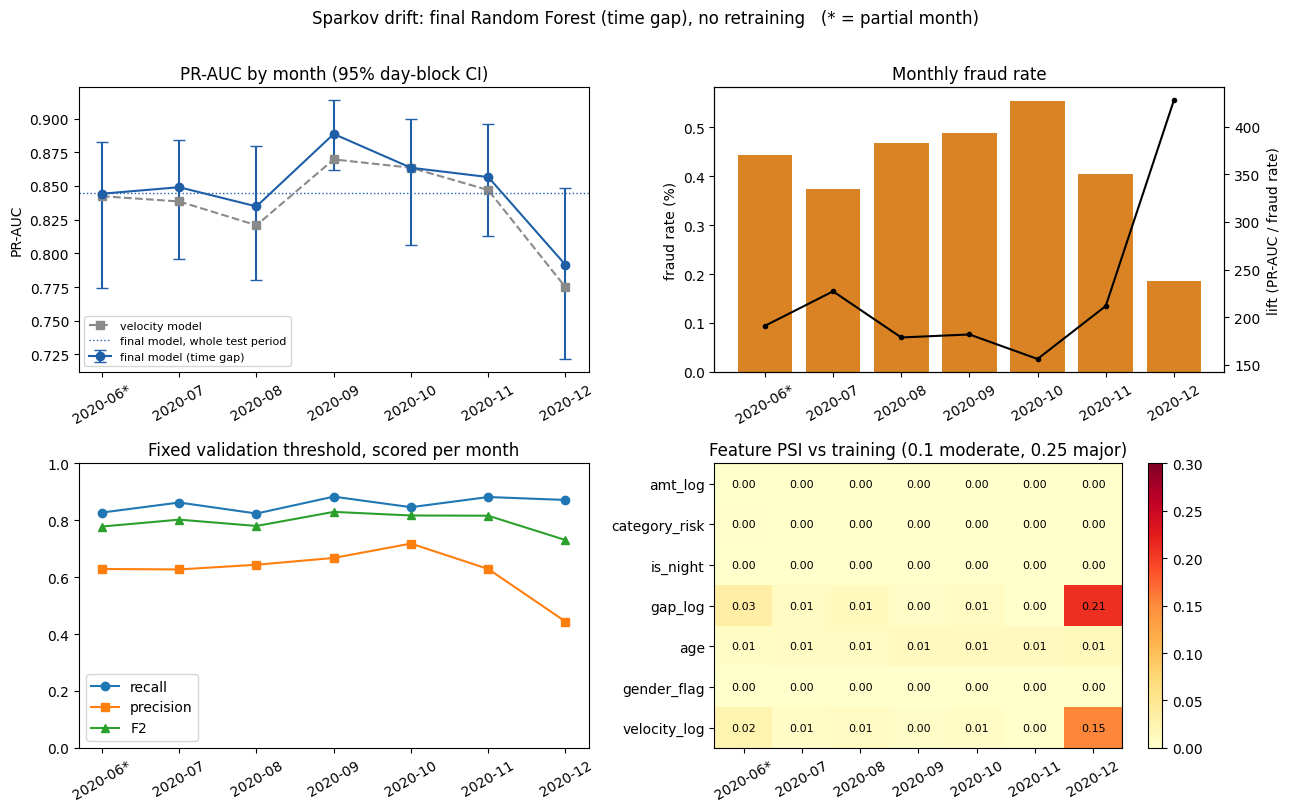

In [20]:
# 3.4 Drift figure: final model, with the velocity model's PR-AUC for comparison
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
x = np.arange(len(monthly))
lab = [m.replace(' (partial)', '*') for m in monthly['Month']]

# 3.4.1 PR-AUC per month
a = ax[0, 0]
a.errorbar(x, monthly['PR-AUC'], yerr=[monthly['PR-AUC'] - monthly['PR-AUC low'], monthly['PR-AUC high'] - monthly['PR-AUC']],
           fmt='o-', capsize=4, color='#1f5fa8', label='final model (time gap)')
a.plot(x, monthly_vel['PR-AUC'], 's--', color='#8a8a8a', label='velocity model')
a.axhline(overall_gap['PR-AUC'], ls=':', color='#1f5fa8', lw=1, label='final model, whole test period')
a.set_xticks(x); a.set_xticklabels(lab, rotation=30); a.set_ylabel('PR-AUC'); a.set_title('PR-AUC by month (95% day-block CI)'); a.legend(fontsize=8)

# 3.4.2 Fraud rate and lift per month
a = ax[0, 1]
a.bar(x, monthly['Fraud rate %'], color='#d98324'); a.set_xticks(x); a.set_xticklabels(lab, rotation=30)
a.set_ylabel('fraud rate (%)'); a.set_title('Monthly fraud rate')
a2 = a.twinx(); a2.plot(x, monthly['Lift (PR-AUC / fraud rate)'], 'k.-'); a2.set_ylabel('lift (PR-AUC / fraud rate)')

# 3.4.3 Operating point at the fixed validation threshold
a = ax[1, 0]
a.plot(x, monthly['Recall'], 'o-', label='recall'); a.plot(x, monthly['Precision'], 's-', label='precision')
a.plot(x, monthly['F2'], '^-', label='F2'); a.set_xticks(x); a.set_xticklabels(lab, rotation=30)
a.set_ylim(0, 1); a.set_title('Fixed validation threshold, scored per month'); a.legend()

# 3.4.4 Input drift
a = ax[1, 1]
im = a.imshow(psi_df.T.values, aspect='auto', cmap='YlOrRd', vmin=0, vmax=0.3)
a.set_xticks(range(len(psi_df))); a.set_xticklabels(lab, rotation=30)
a.set_yticks(range(len(PSI_FEATURES))); a.set_yticklabels(PSI_FEATURES)
for i in range(len(PSI_FEATURES)):
    for j in range(len(psi_df)):
        a.text(j, i, f'{psi_df.T.values[i, j]:.2f}', ha='center', va='center', fontsize=8)
a.set_title('Feature PSI vs training (0.1 moderate, 0.25 major)'); plt.colorbar(im, ax=a)
plt.suptitle('Sparkov drift: final Random Forest (time gap), no retraining   (* = partial month)', y=1.01)
plt.tight_layout(); plt.savefig('results/sparkov_monthly_drift_gap.png', dpi=150, bbox_inches='tight'); plt.show()

### 3.5 Why precision moves: false alarms against the fraud rate

Precision depends on the fraud rate. If the share of genuine transactions that raise an alert stays the same while fraud becomes rarer, the same number of false alarms is spread over fewer frauds and precision falls, even though the model ranks transactions as well as before. This table separates the two effects.

In [21]:
# 3.5 False-alarm rate per month (share of genuine transactions that raise an alert), from the table in 3.2
chk = monthly.copy()
tp = chk['Recall'] * chk['Frauds']
fp = tp * (1 / chk['Precision'] - 1)
chk['False-alarm rate % (of genuine txns)'] = 100 * fp / (chk['Transactions'] - chk['Frauds'])
chk[['Month', 'Transactions', 'Fraud rate %', 'Recall', 'Precision', 'ROC-AUC', 'False-alarm rate % (of genuine txns)']].round(3)

,Month,Transactions,Fraud rate %,Recall,Precision,ROC-AUC,False-alarm rate % (of genuine txns)
0,2020-06 (partial),30058,0.442,0.827,0.629,0.984,0.217
1,2020-07,85848,0.374,0.862,0.627,0.991,0.192
2,2020-08,88759,0.468,0.824,0.644,0.993,0.214
3,2020-09,69533,0.489,0.883,0.668,0.994,0.216
4,2020-10,69348,0.554,0.846,0.718,0.983,0.185
5,2020-11,72635,0.405,0.882,0.629,0.989,0.212
6,2020-12,139538,0.185,0.871,0.444,0.990,0.202


### 3.6 Summary of the drift results

In [22]:
# 3.6 Summary of the drift results, computed from the tables above
fa = chk.set_index('Month')['False-alarm rate % (of genuine txns)']
other = monthly[~monthly['Month'].str.startswith('2020-12')]
dec = monthly[monthly['Month'].str.startswith('2020-12')].iloc[0]
overlap_all = all(not (dec['PR-AUC high'] < r['PR-AUC low'] or r['PR-AUC high'] < dec['PR-AUC low']) for _, r in other.iterrows())
big_psi = psi_df.stack()
big_psi = big_psi[big_psi >= 0.1]
n_better = (monthly_cmp['PR-AUC verdict'] == 'final model better').sum()
n_worse = (monthly_cmp['PR-AUC verdict'] == 'velocity model better').sum()

summary = pd.Series({
    'ROC-AUC range over all months': f"{monthly['ROC-AUC'].min():.3f} to {monthly['ROC-AUC'].max():.3f}",
    'PR-AUC range, June to November': f"{other['PR-AUC'].min():.3f} to {other['PR-AUC'].max():.3f}",
    'PR-AUC in December [95% CI]': f"{dec['PR-AUC']:.3f} [{dec['PR-AUC low']:.3f}, {dec['PR-AUC high']:.3f}]",
    'December interval overlaps every other month': 'yes' if overlap_all else 'no',
    'Fraud rate %, December vs other months': f"{dec['Fraud rate %']:.3f} vs {other['Fraud rate %'].min():.3f} to {other['Fraud rate %'].max():.3f}",
    'Transactions, December vs other full months': f"{dec['Transactions']:,} vs {other.loc[other['Days'] >= 25, 'Transactions'].min():,} to {other.loc[other['Days'] >= 25, 'Transactions'].max():,}",
    'Recall range over all months': f"{monthly['Recall'].min():.3f} to {monthly['Recall'].max():.3f}",
    'Precision, December vs other months': f"{dec['Precision']:.3f} vs {other['Precision'].min():.3f} to {other['Precision'].max():.3f}",
    'False-alarm rate %, December vs other months': f"{fa[dec['Month']]:.3f} vs {fa.drop(dec['Month']).min():.3f} to {fa.drop(dec['Month']).max():.3f}",
    'Features with PSI of 0.1 or more': ', '.join(f'{f} in {m} ({v:.3f})' for (m, f), v in big_psi.items()) or 'none',
    'Months where the final model beats the velocity model (PR-AUC)': f'{n_better} of {len(monthly_cmp)} (velocity model better in {n_worse})',
})
summary.to_csv('results/sparkov_drift_summary.csv', header=['value'])
summary.to_frame('value')

,value
ROC-AUC range over all months,0.983 to 0.994
"PR-AUC range, June to November",0.835 to 0.889
PR-AUC in December [95% CI],"0.791 [0.722, 0.849]"
December interval overlaps every other month,no
"Fraud rate %, December vs other months",0.185 vs 0.374 to 0.554
"Transactions, December vs other full months","139,538 vs 69,348 to 88,759"
Recall range over all months,0.824 to 0.883
"Precision, December vs other months",0.444 vs 0.627 to 0.718
"False-alarm rate %, December vs other months",0.202 vs 0.185 to 0.217
Features with PSI of 0.1 or more,"gap_log in 2020-12 (0.209), velocity_log in 20..."


### 3.7 How we read the drift results

The summary in 3.6 is computed directly from the tables, so it always matches the run. We read it with four checks:

1. **Ranking.** ROC-AUC does not depend on the fraud rate. If it stays near the same level in every month, the model still ranks fraud above genuine transactions as well as it did on validation, and any fall in PR-AUC comes from the fraud rate rather than from a worse model.
2. **Base rate.** PR-AUC and precision fall when fraud becomes rarer. If the false-alarm rate (3.5) stays the same in a month where the fraud rate drops, the lower precision is a base-rate effect: the same share of genuine transactions raises an alert, but there are fewer frauds to catch.
3. **Inputs.** PSI (3.3) shows whether the features themselves moved. For the final model the feature to watch is `gap_log`: a month with more transactions per card (3.3b) has shorter gaps for genuine customers, which is the pattern the model links with fraud. We report this as a possible cause and do not test it further.
4. **Threshold.** If recall stays in the same range in every month, the threshold chosen on validation keeps its operating point and does not need to be re-tuned during the test period.

The month-by-month comparison in 3.2b shows whether the final model's advantage over the velocity model holds across the test period or depends on one month.

**Limits of this result:** Sparkov is simulated by one generator, so stable behaviour is expected and is a statement about the simulator, which is why the real-data check in Section 4 matters. There is one test window (June to December 2020), the model is not retrained, the first month is partial (10 days), and the cause of any December change (higher volume, shorter gaps) is not tested.

## 4. IEEE-CIS (real data): card identifier and temporal features

Only the columns we need are loaded (`train_transaction.csv`; the `test_*` files have no labels, so they cannot be scored). `TransactionDT` is seconds from a hidden reference date, so **hour-of-day and `is_night` are not reliable here and are not used**. The date `2017-11-30` used below is the commonly assumed origin and is only used to order and group days.

In [23]:
# 4.1 Load IEEE-CIS and build the card identifier
IEEE_COLS = ['TransactionID', 'isFraud', 'TransactionDT', 'TransactionAmt', 'ProductCD',
             'card1', 'card4', 'card6', 'addr1', 'D1'] + [f'C{i}' for i in range(1, 15)]
ieee = pd.read_csv('data/ieee/train_transaction.csv', usecols=IEEE_COLS).sort_values('TransactionDT').reset_index(drop=True)
ieee['ts']  = pd.Timestamp('2017-11-30') + pd.to_timedelta(ieee['TransactionDT'], unit='s')   # assumed origin
ieee['day'] = ieee['ts'].dt.floor('D')
ieee['uid'] = make_card_uid(ieee['card1'], ieee['addr1'], ieee['D1'], ieee['TransactionDT'])
print(f"{len(ieee):,} transactions, fraud rate {ieee['isFraud'].mean():.3%}, "
      f"{ieee['ts'].min():%Y-%m-%d} -> {ieee['ts'].max():%Y-%m-%d}")
print(f"missing: addr1 {ieee['addr1'].isna().mean():.1%}, D1 {ieee['D1'].isna().mean():.2%}")

590,540 transactions, fraud rate 3.499%, 2017-12-01 -> 2018-05-31
missing: addr1 11.1%, D1 0.21%


The real data has 590,540 transactions (fraud rate 3.5%) from 2017-12-01 to 2018-05-31. `addr1` is missing for 11.1% of transactions and `D1` for 0.21%; each missing value gets its own code in the card identifier.

### 4.2 Is the identifier meaningful? (diagnostics)

If the identifier really groups transactions of one account, **fraud should cluster inside identifiers**. We compare, for the real identifier and for a **shuffled** one (same group sizes, random members), the share of fraud transactions that sit in an identifier with at least 2 frauds. This uses labels, so it is only a diagnostic, never a feature.

In [24]:
# 4.2 Share of fraud that sits in identifiers holding two or more frauds (real against shuffled)
def cluster_share(uid, y):
    g = pd.DataFrame({'u': uid, 'y': y}).groupby('u')['y'].agg(['size', 'sum'])
    return g.loc[g['sum'] >= 2, 'sum'].sum() / g['sum'].sum(), g

share_real, g_real = cluster_share(ieee['uid'].values, ieee['isFraud'].values)
rng = np.random.default_rng(1)
share_shuf, _ = cluster_share(rng.permutation(ieee['uid'].values), ieee['isFraud'].values)
print(f"distinct card identifiers: {len(g_real):,} (card1 alone has {ieee['card1'].nunique():,})")
print(f"identifiers with a single transaction: {(g_real['size'] == 1).mean():.1%}; "
      f"transactions in identifiers with 2+ transactions: {g_real.loc[g_real['size'] > 1, 'size'].sum() / len(ieee):.1%}")
print(f"share of fraud in identifiers holding 2+ frauds:  real = {share_real:.1%}   shuffled = {share_shuf:.1%}")

distinct card identifiers: 217,850 (card1 alone has 13,553)
identifiers with a single transaction: 57.5%; transactions in identifiers with 2+ transactions: 78.8%
share of fraud in identifiers holding 2+ frauds:  real = 78.0%   shuffled = 20.7%


The identifier groups real accounts: 78.0% of fraud transactions sit in an identifier that holds two or more frauds, against 20.7% when the identifiers are shuffled. There are 217,850 identifiers, against 13,553 values of `card1` alone.

In [25]:
# 4.3 Features (backward-looking, no labels), plus a PLACEBO version built on shuffled identifiers
tf = temporal_features(ieee['uid'].values, ieee['TransactionDT'].values, ieee['TransactionAmt'].values)
rng = np.random.default_rng(7)
tf_pl = temporal_features(rng.permutation(ieee['uid'].values), ieee['TransactionDT'].values,
                          ieee['TransactionAmt'].values).add_suffix('_pl')
ieee = pd.concat([ieee, tf, tf_pl], axis=1)
ieee['amt_log'] = np.log1p(ieee['TransactionAmt'])
ieee['acct_age_days'] = ieee['D1'].fillna(-1)

# time split: last 20% = test; of the first 80%, the last 20% (by time) = validation
n = len(ieee)
test_i = ieee.iloc[int(n * 0.8):]
tv = ieee.iloc[:int(n * 0.8)]
tr_i, val_i, cut_i = chronological_val_split(tv, 'ts', val_frac=0.2)

cats = []
for c in ['ProductCD', 'card4', 'card6']:                      # categories fixed from the training part only
    for v in sorted(tr_i[c].dropna().unique()):
        ieee[f'{c}={v}'] = (ieee[c] == v).astype(float); cats.append(f'{c}={v}')
tr_i, val_i, test_i = ieee.loc[tr_i.index], ieee.loc[val_i.index], ieee.loc[test_i.index]

# --- Card-history burn-in -------------------------------------------------------------------------
# The data starts on a fixed day. A card whose earlier transactions happened BEFORE that day looks "new"
# (is_first = 1, prior count 0) in the first weeks, so the timing features would mean something different in
# training than in validation/test. The features are still computed on ALL rows (so later rows see the full
# history); we only skip the first BURN_IN_DAYS days as TRAINING rows.
week_ = ((ieee['ts'] - ieee['ts'].min()).dt.days // 7).rename('week')
hist = ieee.groupby(week_).agg(transactions=('isFraud', 'size'), share_that_look_like_a_first_transaction=('is_first', 'mean'))
print('Share of transactions that look like the first one of their card, by week since the data starts:')
display(hist.loc[[w for w in [0, 1, 2, 3, 4, 6, 8, 12, 16, 20, 25] if w in hist.index]].round(3))
hist.to_csv('results/ieee_card_history_by_week.csv')
burn_cut = ieee['ts'].min() + pd.Timedelta(days=BURN_IN_DAYS)
n_before, first_before = len(tr_i), tr_i['is_first'].mean()
tr_i = tr_i[tr_i['ts'] >= burn_cut]
print(f"Training rows: {n_before:,} -> {len(tr_i):,} after skipping the first {BURN_IN_DAYS} days. "
      f"Share of first-seen rows: train {first_before:.3f} -> {tr_i['is_first'].mean():.3f} "
      f"(validation {val_i['is_first'].mean():.3f}, test {test_i['is_first'].mean():.3f})")
for nm, d_ in [('train', tr_i), ('val', val_i), ('test', test_i)]:
    print(f"{nm:5s} rows={len(d_):>8,}  fraud rate={d_['isFraud'].mean():.3%}  {d_['ts'].min():%Y-%m-%d} -> {d_['ts'].max():%Y-%m-%d}")

# descriptive: fraud rate by temporal-feature bucket (TRAINING part only)
g_ = np.expm1(tr_i['gap_log']).where(tr_i['is_first'] == 0)
print('\nFraud rate by seconds since the card\'s previous transaction (training part):')
print(tr_i.groupby(pd.cut(g_, [-1, 60, 600, 3600, 86400, 7 * 86400, 1e12]))['isFraud'].agg(['mean', 'size']).round(4))
print('\nFraud rate by number of earlier transactions on the card in the last 24 h:')
print(tr_i.groupby(pd.cut(np.expm1(tr_i['burst_24h']), [-1, 0, 1, 3, 10, 1e9]))['isFraud'].agg(['mean', 'size']).round(4))

Share of transactions that look like the first one of their card, by week since the data starts:


,transactions,share_that_look_like_a_first_transaction
week,,
0,27596,0.660
1,28463,0.568
2,35701,0.483
3,34906,0.449
4,24539,0.367
6,20564,0.372
8,21432,0.347
12,22391,0.322
16,21078,0.310


Training rows: 389,881 -> 255,542 after skipping the first 30 days. Share of first-seen rows: train 0.404 -> 0.342 (validation 0.303, test 0.299)
train rows= 255,542  fraud rate=3.898%  2017-12-31 -> 2018-03-23
val   rows=  82,551  fraud rate=3.922%  2018-03-23 -> 2018-04-20
test  rows= 118,108  fraud rate=3.441%  2018-04-20 -> 2018-05-31

Fraud rate by seconds since the card's previous transaction (training part):
                               mean   size
gap_log                                   
(-1.0, 60.0]                 0.1418   3512
(60.0, 600.0]                0.0808  18614
(600.0, 3600.0]              0.0672  16270
(3600.0, 86400.0]            0.0606  33255
(86400.0, 604800.0]          0.0350  33282
(604800.0, 1000000000000.0]  0.0122  63334

Fraud rate by number of earlier transactions on the card in the last 24 h:
                        mean    size
burst_24h                           
(-1.0, 0.0]           0.0264  183891
(0.0, 1.0]            0.0557   34249
(1.0, 3.0]   

**What the table shows.**

* **The timing features carry fraud signal on real data.** When a card's previous transaction was under a minute earlier, 14.2% of transactions are fraud, against 1.2% when it was more than a week earlier. Fraud also rises with the number of recent transactions on the card, from 2.6% with none in the last 24 hours to 9.9% with 4 to 10.
* **The first weeks need a burn-in.** In week 0, 66% of transactions look like a card's first, falling to about 30% from week 12 onwards, because earlier history lies before the start of the data. Skipping the first 30 days as training rows (389,881 to 255,542 rows) brings the share of first-seen rows in training from 0.404 to 0.342, close to validation (0.303) and test (0.299).

### 4.4 Does the temporal signal transfer? Feature-set comparison

Four model settings are compared on the same feature sets, because the answer can depend on the model:

* **LightGBM**: the standard model for IEEE-CIS (400 trees, learning rate 0.05, no class weights; `boosting_comparison.ipynb` found that weighting hurts LightGBM).
* **Random Forest, `max_features` chosen on validation.** The paper's Random Forest uses `max_features=3`, which was tuned for the 6 Sparkov features. The IEEE sets have 14 to 35 features, so 3 per split would unfairly penalise the bigger sets. For each feature set we therefore pick `max_features` from {3, sqrt, 0.3, 0.6} using the **validation part only**.
* **Random Forest with `max_features=3`** (the Sparkov setting), kept as a sensitivity check so the effect of this setting is visible.
* **Logistic Regression** as a linear reference.

Random Forest and LightGBM use 3 seeds; Logistic Regression uses 1 seed because it is deterministic. Intervals use 200 day-block resamples.

Feature sets:

| Set | Features |
|---|---|
| **A** | base: log amount, `ProductCD`, `card4`, `card6` |
| **B** | A + time-gap |
| **C** | A + burst counts (+ prior count) |
| **D** | A + time-gap + bursts |
| **E** | D + amount versus the card's own history |
| **F** | E + account age (`D1`) |
| **G** | A + IEEE's own count columns `C1`-`C14` (reference: counts engineered by the data provider) |
| **H** | G + E's temporal features (do ours add anything **on top of** the provider's counts?) |
| **P** | **placebo**: E's features recomputed on *shuffled* identifiers. If P matches E, the gain was not from the card grouping. |

Every difference is a **paired** bootstrap difference on the same resampled test days. Training skips the first 30 days (card-history burn-in, see 4.3).

In [26]:
# 4.5 Feature sets and the evaluation helpers
BASE = ['amt_log'] + cats
GAP, BUR, AH = ['gap_log', 'is_first'], ['prior_count_log', 'burst_10m', 'burst_1h', 'burst_24h'], ['amt_vs_hist']
CCOLS = [f'C{i}' for i in range(1, 15)]
IEEE_SETS = {
    'A': BASE, 'B': BASE + GAP, 'C': BASE + BUR, 'D': BASE + GAP + BUR, 'E': BASE + GAP + BUR + AH,
    'F': BASE + GAP + BUR + AH + ['acct_age_days'],
    'G': BASE + CCOLS, 'H': BASE + CCOLS + GAP + BUR + AH,
    'P': BASE + [c + '_pl' for c in GAP + BUR + AH],
}
LABEL = {'A': 'A base', 'B': 'B +gap', 'C': 'C +bursts', 'D': 'D +gap+bursts', 'E': 'E +amt vs history',
         'F': 'F +account age', 'G': 'G base+C1-C14', 'H': 'H G+temporal', 'P': 'P placebo of E'}

def eval_sets(tag, sets, tr, va, te, target, make_model, seeds, ckpt, n_boot, by_key=False):
    """by_key=True: make_model(key) returns the seed -> model function for that feature set."""
    runs, boots, summ = {}, {}, {}
    for key, cols in sets.items():
        mm = make_model(key) if by_key else make_model
        h = hashlib.md5((','.join(cols) + str(len(tr)) + str(sorted(mm(0).get_params().items()))).encode()).hexdigest()[:6]
        runs[key] = run_seeds(f'{tag}_{key}_{h}', mm, tr[cols], tr[target], va[cols], va[target],
                              te[cols], seeds, checkpoint_dir=ckpt)
        pr = [(r['test_proba'], r['threshold']) for r in runs[key]]
        boots[key] = bootstrap_model(te[target].values, pr, te['day'].values, n_boot=n_boot, boot_seed=2026)
        summ[key] = summarise(te[target].values, pr, boots[key])
    return runs, boots, summ

def results_table(summ, base_rate, label):
    return pd.DataFrame([{'Feature set': label[k], 'PR-AUC [95% CI]': format_ci(s, 'PR-AUC'),
                          'Lift over base rate': round(s['PR-AUC'] / base_rate, 2),
                          'F2 [95% CI]': format_ci(s, 'F2'), 'MCC [95% CI]': format_ci(s, 'MCC')}
                         for k, s in summ.items()])

def uplift_table(boots, comparisons, label, who):
    rows = []
    for a, b in comparisons:
        row = {'Model': who, 'Comparison': f'{label[a]}  minus  {label[b]}'}
        for m in ['PR-AUC', 'F2']:
            d = paired_difference(boots[a], boots[b], m)
            row[f'{m} difference [95% CI]'] = f"{d['mean diff']:+.4f} [{d['CI low']:+.4f}, {d['CI high']:+.4f}]"
            row[f'{m} real?'] = 'yes' if (d['CI low'] > 0 or d['CI high'] < 0) else 'no (CI includes 0)'
        rows.append(row)
    return pd.DataFrame(rows)

def choose_max_features(sets, tr, va, target, grid, seed=0):
    """Pick max_features for each feature set from the VALIDATION part only (one seed, few trees)."""
    chosen, rows = {}, []
    for key, cols in sets.items():
        sc = {}
        for mf in grid:
            m = RandomForestClassifier(n_estimators=N_TREES_SEL, max_features=mf, min_samples_leaf=5,
                                       random_state=seed, n_jobs=-1).fit(tr[cols], tr[target])
            sc[mf] = average_precision_score(va[target], m.predict_proba(va[cols])[:, 1])
        chosen[key] = max(sc, key=sc.get)
        rows.append({'set': key, 'n features': len(cols), **{f'max_features={g}': round(v, 4) for g, v in sc.items()},
                     'chosen': f'max_features={chosen[key]}'})
    return chosen, pd.DataFrame(rows)

rf_by_key = lambda sel: (lambda key: (lambda s: RandomForestClassifier(n_estimators=N_TREES_ABL, max_features=sel[key],
                                                                      min_samples_leaf=5, random_state=s, n_jobs=-1)))
make_rf3 = lambda s: RandomForestClassifier(n_estimators=N_TREES_ABL, max_features=3, min_samples_leaf=5,
                                            random_state=s, n_jobs=-1)
make_lgb = lambda s: LGBMClassifier(n_estimators=N_LGB, learning_rate=0.05, num_leaves=31, min_child_samples=50,
                                    subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0,
                                    random_state=s, n_jobs=-1, verbose=-1)
make_lr = lambda s: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
IEEE_CMP = [('B', 'A'), ('C', 'A'), ('D', 'A'), ('E', 'A'), ('F', 'A'), ('P', 'A'), ('H', 'G')]
base_rate_i = test_i['isFraud'].mean()
print(f'IEEE test base rate (a model with no skill scores a PR-AUC of about this): {base_rate_i:.4f}')

IEEE test base rate (a model with no skill scores a PR-AUC of about this): 0.0344


The IEEE test base rate is 0.0344: a model with no skill scores a PR-AUC of about this value, so lift over the base rate is shown next to every PR-AUC.

In [32]:
# 4.6a Choose max_features for the Random Forest on the VALIDATION part (the test part is not touched)
mf_i, mf_table_i = choose_max_features(IEEE_SETS, tr_i, val_i, 'isFraud', MF_GRID_IEEE)
mf_table_i.to_csv('results/ieee_rf_max_features_selection.csv', index=False)
mf_table_i

,set,n features,max_features=3,max_features=sqrt,max_features=0.3,max_features=0.6,chosen
0,A,14,0.1507,0.1507,0.1462,0.1439,max_features=sqrt
1,B,16,0.1597,0.1588,0.1588,0.1608,max_features=0.6
2,C,18,0.1478,0.1454,0.1430,0.1408,max_features=3
3,D,20,0.1567,0.1575,0.1577,0.1588,max_features=0.6
4,E,21,0.1699,0.1676,0.1700,0.1729,max_features=0.6
5,F,22,0.1881,0.1836,0.1822,0.1744,max_features=3
6,G,28,0.5336,0.5331,0.5309,0.5190,max_features=3
7,H,35,0.5165,0.5215,0.5327,0.5210,max_features=0.3
8,P,21,0.1262,0.1247,0.1240,0.1269,max_features=0.6


On validation the `max_features` settings differ by only 0.002 to 0.016 PR-AUC within each set. The chosen values are 0.6 for B, D, E and P; 3 for C, F and G; sqrt for A; and 0.3 for H.

In [34]:
# 4.6b LightGBM on the IEEE feature sets (the standard model for this dataset)
lgb_runs_i, lgb_boot_i, lgb_summ_i = eval_sets('ieee_lgbm', IEEE_SETS, tr_i, val_i, test_i, 'isFraud',
                                               make_lgb, ABL_SEEDS, ABL_CKPT, N_BOOT)
ieee_lgb_table = results_table(lgb_summ_i, base_rate_i, LABEL)
ieee_lgb_table.to_csv('results/ieee_lgbm_feature_sets.csv', index=False)
ieee_lgb_table

ieee_lgbm_A_656abf seed 42: loaded from checkpoint
ieee_lgbm_A_656abf seed 43: loaded from checkpoint
ieee_lgbm_A_656abf seed 44: loaded from checkpoint
ieee_lgbm_B_673655 seed 42: loaded from checkpoint
ieee_lgbm_B_673655 seed 43: loaded from checkpoint
ieee_lgbm_B_673655 seed 44: loaded from checkpoint
ieee_lgbm_C_c18e7e seed 42: loaded from checkpoint
ieee_lgbm_C_c18e7e seed 43: loaded from checkpoint
ieee_lgbm_C_c18e7e seed 44: loaded from checkpoint
ieee_lgbm_D_25bb9c seed 42: loaded from checkpoint
ieee_lgbm_D_25bb9c seed 43: loaded from checkpoint
ieee_lgbm_D_25bb9c seed 44: loaded from checkpoint
ieee_lgbm_E_69fea1 seed 42: loaded from checkpoint
ieee_lgbm_E_69fea1 seed 43: loaded from checkpoint
ieee_lgbm_E_69fea1 seed 44: loaded from checkpoint
ieee_lgbm_F_63abfa seed 42: loaded from checkpoint
ieee_lgbm_F_63abfa seed 43: loaded from checkpoint
ieee_lgbm_F_63abfa seed 44: loaded from checkpoint
ieee_lgbm_G_e17dca seed 42: loaded from checkpoint
ieee_lgbm_G_e17dca seed 43: loa

,Feature set,PR-AUC [95% CI],Lift over base rate,F2 [95% CI],MCC [95% CI]
0,A base,"0.1198 [0.1043, 0.1362]",3.48,"0.2846 [0.2644, 0.3051]","0.1698 [0.1546, 0.1860]"
1,B +gap,"0.1056 [0.0862, 0.1355]",3.07,"0.2952 [0.2748, 0.3124]","0.1793 [0.1632, 0.1946]"
2,C +bursts,"0.1018 [0.0836, 0.1290]",2.96,"0.2956 [0.2705, 0.3148]","0.1795 [0.1604, 0.1949]"
3,D +gap+bursts,"0.1068 [0.0874, 0.1369]",3.10,"0.2976 [0.2753, 0.3169]","0.1815 [0.1625, 0.1967]"
4,E +amt vs history,"0.1117 [0.0910, 0.1411]",3.25,"0.3014 [0.2780, 0.3208]","0.1850 [0.1655, 0.2003]"
5,F +account age,"0.1419 [0.1234, 0.1612]",4.12,"0.3150 [0.2932, 0.3324]","0.1973 [0.1809, 0.2121]"
6,G base+C1-C14,"0.4287 [0.3879, 0.4620]",12.46,"0.4469 [0.4202, 0.4674]","0.3596 [0.3353, 0.3798]"
7,H G+temporal,"0.4413 [0.4030, 0.4748]",12.83,"0.4695 [0.4471, 0.4896]","0.3769 [0.3535, 0.3963]"
8,P placebo of E,"0.1200 [0.1059, 0.1346]",3.49,"0.2866 [0.2660, 0.3072]","0.1718 [0.1563, 0.1864]"


**LightGBM.** With IEEE's own count columns the model reaches PR-AUC 0.4287 (G), and 0.4413 after adding our temporal features (H). Without the count columns all sets stay between 0.10 and 0.14. Adding account age (F) gives the best of the basic sets (0.1419). The placebo (P, 0.1200) matches the base set (A, 0.1198).

In [35]:
print('mf_i' in globals(), 'mf_table_i' in globals(), 'tr_i' in globals(), 'IEEE_SETS' in globals())

True True True True


In [36]:
# 4.6c Random Forest with max_features chosen on validation (longest cell of the IEEE part)
rf_runs_i, rf_boot_i, rf_summ_i = eval_sets('ieee_rf_tuned', IEEE_SETS, tr_i, val_i, test_i, 'isFraud',
                                            rf_by_key(mf_i), ABL_SEEDS, ABL_CKPT, N_BOOT, by_key=True)
ieee_rf_table = results_table(rf_summ_i, base_rate_i, LABEL)
ieee_rf_table.to_csv('results/ieee_rf_feature_sets.csv', index=False)
ieee_rf_table

ieee_rf_tuned_A_2ddb89 seed 42: loaded from checkpoint
ieee_rf_tuned_A_2ddb89 seed 43: loaded from checkpoint
ieee_rf_tuned_A_2ddb89 seed 44: loaded from checkpoint
ieee_rf_tuned_B_f1b9e1 seed 42: loaded from checkpoint
ieee_rf_tuned_B_f1b9e1 seed 43: loaded from checkpoint
ieee_rf_tuned_B_f1b9e1 seed 44: loaded from checkpoint
ieee_rf_tuned_C_252283 seed 42: loaded from checkpoint
ieee_rf_tuned_C_252283 seed 43: loaded from checkpoint
ieee_rf_tuned_C_252283 seed 44: loaded from checkpoint
ieee_rf_tuned_D_d224b8 seed 42: loaded from checkpoint
ieee_rf_tuned_D_d224b8 seed 43: loaded from checkpoint
ieee_rf_tuned_D_d224b8 seed 44: loaded from checkpoint
ieee_rf_tuned_E_801bfb seed 42: loaded from checkpoint
ieee_rf_tuned_E_801bfb seed 43: loaded from checkpoint
ieee_rf_tuned_E_801bfb seed 44: loaded from checkpoint
ieee_rf_tuned_F_0e398c seed 42: loaded from checkpoint
ieee_rf_tuned_F_0e398c seed 43: loaded from checkpoint
ieee_rf_tuned_F_0e398c seed 44: loaded from checkpoint
ieee_rf_tu

,Feature set,PR-AUC [95% CI],Lift over base rate,F2 [95% CI],MCC [95% CI]
0,A base,"0.1054 [0.0950, 0.1173]",3.06,"0.2528 [0.2369, 0.2712]","0.1458 [0.1338, 0.1605]"
1,B +gap,"0.0935 [0.0782, 0.1127]",2.72,"0.2549 [0.2363, 0.2708]","0.1425 [0.1285, 0.1554]"
2,C +bursts,"0.0880 [0.0730, 0.1068]",2.56,"0.2732 [0.2541, 0.2917]","0.1587 [0.1444, 0.1740]"
3,D +gap+bursts,"0.0925 [0.0779, 0.1126]",2.69,"0.2642 [0.2438, 0.2796]","0.1510 [0.1353, 0.1640]"
4,E +amt vs history,"0.0945 [0.0783, 0.1174]",2.75,"0.2749 [0.2537, 0.2926]","0.1611 [0.1435, 0.1743]"
5,F +account age,"0.1067 [0.0873, 0.1347]",3.10,"0.3037 [0.2833, 0.3241]","0.1870 [0.1709, 0.2013]"
6,G base+C1-C14,"0.4167 [0.3816, 0.4508]",12.11,"0.4235 [0.3919, 0.4537]","0.3162 [0.2835, 0.3533]"
7,H G+temporal,"0.4180 [0.3770, 0.4628]",12.15,"0.4408 [0.4076, 0.4751]","0.3417 [0.3018, 0.3907]"
8,P placebo of E,"0.0968 [0.0865, 0.1073]",2.81,"0.2326 [0.2173, 0.2486]","0.1201 [0.1088, 0.1324]"


**Random Forest, `max_features` tuned.** G scores 0.4167 and H 0.4180, so on PR-AUC the temporal features add almost nothing on top of the count columns for this model. F2 and MCC rise from G to H (0.4235 to 0.4408, and 0.3162 to 0.3417). The placebo (0.0968) is below the base set (0.1054).

In [37]:
# 4.6d Sensitivity check: Random Forest with the Sparkov setting max_features=3
rf3_runs_i, rf3_boot_i, rf3_summ_i = eval_sets('ieee_rf3', IEEE_SETS, tr_i, val_i, test_i, 'isFraud',
                                               make_rf3, ABL_SEEDS, ABL_CKPT, N_BOOT)
ieee_rf3_table = results_table(rf3_summ_i, base_rate_i, LABEL)
ieee_rf3_table.to_csv('results/ieee_rf_maxfeat3_feature_sets.csv', index=False)
ieee_rf3_table

ieee_rf3_A_35326b seed 42: loaded from checkpoint
ieee_rf3_A_35326b seed 43: loaded from checkpoint
ieee_rf3_A_35326b seed 44: loaded from checkpoint
ieee_rf3_B_06866f seed 42: loaded from checkpoint
ieee_rf3_B_06866f seed 43: loaded from checkpoint
ieee_rf3_B_06866f seed 44: loaded from checkpoint
ieee_rf3_C_252283 seed 42: loaded from checkpoint
ieee_rf3_C_252283 seed 43: loaded from checkpoint
ieee_rf3_C_252283 seed 44: loaded from checkpoint
ieee_rf3_D_6d5213 seed 42: loaded from checkpoint
ieee_rf3_D_6d5213 seed 43: loaded from checkpoint
ieee_rf3_D_6d5213 seed 44: loaded from checkpoint
ieee_rf3_E_55bea2 seed 42: loaded from checkpoint
ieee_rf3_E_55bea2 seed 43: loaded from checkpoint
ieee_rf3_E_55bea2 seed 44: loaded from checkpoint
ieee_rf3_F_0e398c seed 42: loaded from checkpoint
ieee_rf3_F_0e398c seed 43: loaded from checkpoint
ieee_rf3_F_0e398c seed 44: loaded from checkpoint
ieee_rf3_G_82b69b seed 42: loaded from checkpoint
ieee_rf3_G_82b69b seed 43: loaded from checkpoint


,Feature set,PR-AUC [95% CI],Lift over base rate,F2 [95% CI],MCC [95% CI]
0,A base,"0.1054 [0.0950, 0.1173]",3.06,"0.2528 [0.2369, 0.2712]","0.1458 [0.1338, 0.1605]"
1,B +gap,"0.0898 [0.0736, 0.1122]",2.61,"0.2648 [0.2471, 0.2806]","0.1508 [0.1358, 0.1622]"
2,C +bursts,"0.0880 [0.0730, 0.1068]",2.56,"0.2732 [0.2541, 0.2917]","0.1587 [0.1444, 0.1740]"
3,D +gap+bursts,"0.0950 [0.0789, 0.1189]",2.76,"0.2830 [0.2603, 0.3033]","0.1682 [0.1519, 0.1829]"
4,E +amt vs history,"0.0964 [0.0791, 0.1225]",2.80,"0.2864 [0.2670, 0.3073]","0.1711 [0.1557, 0.1888]"
5,F +account age,"0.1067 [0.0873, 0.1347]",3.10,"0.3037 [0.2833, 0.3241]","0.1870 [0.1709, 0.2013]"
6,G base+C1-C14,"0.4167 [0.3816, 0.4508]",12.11,"0.4235 [0.3919, 0.4537]","0.3162 [0.2835, 0.3533]"
7,H G+temporal,"0.3785 [0.3366, 0.4349]",11.00,"0.4278 [0.3956, 0.4609]","0.3267 [0.2896, 0.3726]"
8,P placebo of E,"0.0897 [0.0783, 0.1016]",2.61,"0.2479 [0.2307, 0.2641]","0.1353 [0.1225, 0.1482]"


**Random Forest, `max_features=3`.** G scores 0.4167 and H 0.3785. The drop from G to H does not appear with `max_features` tuned (4.6c), so it comes from the setting: with 35 features, 3 per split rarely reaches the strong count columns.

In [38]:
# 4.7 Logistic Regression on the same sets (a linear model cannot use gaps/bursts in a non-linear way, so this is a reference)
lr_runs_i, lr_boot_i, lr_summ_i = eval_sets('ieee_lr', IEEE_SETS, tr_i, val_i, test_i, 'isFraud',
                                            make_lr, [42], ABL_CKPT, N_BOOT)
ieee_lr_table = results_table(lr_summ_i, base_rate_i, LABEL)
ieee_lr_table.to_csv('results/ieee_lr_feature_sets.csv', index=False)
ieee_lr_table

ieee_lr_A_c3a9d8 seed 42: loaded from checkpoint
ieee_lr_B_8f6c88 seed 42: loaded from checkpoint
ieee_lr_C_4221f8 seed 42: loaded from checkpoint
ieee_lr_D_f45505 seed 42: loaded from checkpoint
ieee_lr_E_471be4 seed 42: loaded from checkpoint
ieee_lr_F_d38ec0 seed 42: loaded from checkpoint
ieee_lr_G_5c50e0 seed 42: loaded from checkpoint
ieee_lr_H_c11163 seed 42: loaded from checkpoint
ieee_lr_P_38291c seed 42: loaded from checkpoint


,Feature set,PR-AUC [95% CI],Lift over base rate,F2 [95% CI],MCC [95% CI]
0,A base,"0.1127 [0.1013, 0.1263]",3.27,"0.2903 [0.2665, 0.3134]","0.1745 [0.1546, 0.1929]"
1,B +gap,"0.0915 [0.0784, 0.1106]",2.66,"0.2875 [0.2652, 0.3084]","0.1721 [0.1551, 0.1893]"
2,C +bursts,"0.0881 [0.0744, 0.1064]",2.56,"0.2781 [0.2552, 0.3004]","0.1648 [0.1468, 0.1833]"
3,D +gap+bursts,"0.0991 [0.0869, 0.1155]",2.88,"0.2835 [0.2598, 0.3045]","0.1682 [0.1502, 0.1851]"
4,E +amt vs history,"0.1006 [0.0884, 0.1165]",2.92,"0.2864 [0.2638, 0.3071]","0.1709 [0.1533, 0.1879]"
5,F +account age,"0.1030 [0.0889, 0.1206]",2.99,"0.2906 [0.2678, 0.3136]","0.1755 [0.1578, 0.1946]"
6,G base+C1-C14,"0.3289 [0.2872, 0.3725]",9.56,"0.4005 [0.3718, 0.4254]","0.3129 [0.2869, 0.3376]"
7,H G+temporal,"0.3074 [0.2679, 0.3494]",8.93,"0.3799 [0.3528, 0.4034]","0.2720 [0.2495, 0.2928]"
8,P placebo of E,"0.1127 [0.1011, 0.1264]",3.27,"0.2887 [0.2638, 0.3125]","0.1731 [0.1532, 0.1912]"


**Logistic Regression.** G scores 0.3289 and H 0.3074, and every basic set with temporal features scores below the base set. A linear model cannot use thresholds such as "under a minute", so these features do not help it.

In [39]:
# 4.8 Paired differences (this is the table that answers "does it transfer?")
ieee_uplift = pd.concat([uplift_table(lgb_boot_i, IEEE_CMP, LABEL, 'LightGBM'),
                         uplift_table(rf_boot_i, IEEE_CMP, LABEL, 'Random Forest (max_features tuned)'),
                         uplift_table(rf3_boot_i, IEEE_CMP, LABEL, 'Random Forest (max_features=3)'),
                         uplift_table(lr_boot_i, IEEE_CMP, LABEL, 'Logistic Regression')], ignore_index=True)
ieee_uplift.to_csv('results/ieee_uplift.csv', index=False)
ieee_uplift

,Model,Comparison,PR-AUC difference [95% CI],PR-AUC real?,F2 difference [95% CI],F2 real?
0,LightGBM,B +gap minus A base,"-0.0127 [-0.0263, +0.0076]",no (CI includes 0),"+0.0107 [+0.0026, +0.0191]",yes
1,LightGBM,C +bursts minus A base,"-0.0164 [-0.0293, +0.0043]",no (CI includes 0),"+0.0113 [+0.0019, +0.0199]",yes
2,LightGBM,D +gap+bursts minus A base,"-0.0112 [-0.0262, +0.0120]",no (CI includes 0),"+0.0131 [+0.0040, +0.0216]",yes
3,LightGBM,E +amt vs history minus A base,"-0.0064 [-0.0217, +0.0153]",no (CI includes 0),"+0.0169 [+0.0064, +0.0281]",yes
4,LightGBM,F +account age minus A base,"+0.0221 [+0.0121, +0.0320]",yes,"+0.0305 [+0.0203, +0.0404]",yes
5,LightGBM,P placebo of E minus A base,"-0.0000 [-0.0036, +0.0049]",no (CI includes 0),"+0.0018 [-0.0020, +0.0049]",no (CI includes 0)
6,LightGBM,H G+temporal minus G base+C1-C14,"+0.0128 [+0.0070, +0.0179]",yes,"+0.0232 [+0.0161, +0.0310]",yes
7,Random Forest (max_features tuned),B +gap minus A base,"-0.0109 [-0.0255, +0.0063]",no (CI includes 0),"+0.0019 [-0.0135, +0.0173]",no (CI includes 0)
8,Random Forest (max_features tuned),C +bursts minus A base,"-0.0162 [-0.0305, +0.0012]",no (CI includes 0),"+0.0206 [+0.0063, +0.0365]",yes
9,Random Forest (max_features tuned),D +gap+bursts minus A base,"-0.0116 [-0.0259, +0.0094]",no (CI includes 0),"+0.0113 [-0.0044, +0.0282]",no (CI includes 0)


**Paired differences.** With LightGBM, adding our temporal features on top of IEEE's count columns (H minus G) raises PR-AUC by +0.0128 [+0.0070, +0.0179] and F2 by +0.0232 [+0.0161, +0.0310]; both intervals are above 0. The placebo gives no change. With the tuned Random Forest the same comparison shows no clear PR-AUC change (+0.0018 [−0.0069, +0.0118]) but a real F2 gain (+0.0177 [+0.0090, +0.0258]), and the placebo makes the model worse (PR-AUC −0.0088 [−0.0139, −0.0032]).

## 5. The same temporal features on Sparkov (like-for-like comparison)

Sparkov already has the exact card (`cc_num`), so here the identifier is exact rather than approximated, and Sparkov has **velocity** (spatial). We test four sets with the same protocol: the five non-temporal features without velocity (**SA**), plus the temporal features (**SB**), plus velocity (**SC**), and both (**SD**). This shows how much of the Sparkov gain comes from geography versus time, and whether the temporal part behaves the same on synthetic and real data.

The same two choices as on IEEE-CIS apply: the **30-day burn-in** (on Sparkov it only removes the first weeks of 2019, where the card history is cut off) and **`max_features` chosen on validation** for each set (SB and SD have 12 and 13 features, so `max_features=3` would penalise them). LightGBM is run as well.

These sets are not the final model: SB uses all seven temporal features, while the final model uses only `gap_log`, and this section trains 100 trees on 3 seeds. The section answers the question in the paper's title (spatial or temporal), and the final model's own numbers come from `final_model_gap.ipynb`.

Runtime note: this is the longest part of the notebook (about 1 million training rows per fit). The saved checkpoints make it safe to resume.

In [40]:
# 5.1 Sparkov feature sets, burn-in, and the choice of max_features on validation
SP_BASE = ['amt_log', 'category_risk', 'is_night', 'age', 'gender_flag']
SP_T = ['gap_log', 'is_first', 'prior_count_log', 'burst_10m', 'burst_1h', 'burst_24h', 'amt_vs_hist']
SP_SETS = {'SA': SP_BASE, 'SB': SP_BASE + SP_T, 'SC': SP_BASE + ['velocity_log'], 'SD': SP_BASE + SP_T + ['velocity_log']}
SP_LABEL = {'SA': 'SA base (no velocity, no temporal)', 'SB': 'SB +temporal', 'SC': 'SC +velocity', 'SD': 'SD +velocity+temporal'}
sp_te = sparkov_test.copy()

t0_sp = pd.to_datetime(train_sub[TIME]).min()
train_sub_b = train_sub[pd.to_datetime(train_sub[TIME]) >= t0_sp + pd.Timedelta(days=BURN_IN_DAYS)]
print(f"Sparkov training rows: {len(train_sub):,} -> {len(train_sub_b):,} after skipping the first {BURN_IN_DAYS} days. "
      f"Share of first-seen rows: before {train_sub['is_first'].mean():.4f}, after {train_sub_b['is_first'].mean():.4f}, "
      f"test {sp_te['is_first'].mean():.4f}")

mf_sp, mf_table_sp = choose_max_features(SP_SETS, train_sub_b, val, 'is_fraud', MF_GRID_SP)
mf_table_sp.to_csv('results/sparkov_rf_max_features_selection.csv', index=False)
mf_table_sp

Sparkov training rows: 1,036,901 -> 985,603 after skipping the first 30 days. Share of first-seen rows: before 0.0009, after 0.0001, test 0.0000


,set,n features,max_features=3,max_features=sqrt,max_features=0.5,chosen
0,SA,5,0.8586,0.8554,0.8554,max_features=3
1,SB,12,0.8868,0.8868,0.8955,max_features=0.5
2,SC,6,0.8730,0.8633,0.8730,max_features=3
3,SD,13,0.8745,0.8745,0.8954,max_features=0.5


Skipping the first 30 days removes 51,298 of 1,036,901 training rows (985,603 remain), and the share of first-seen rows falls from 0.0009 to 0.0001. On validation, SA keeps `max_features=3` and the three larger sets choose 0.5.

In [41]:
# 5.2 LightGBM and Random Forest (max_features tuned) on the four Sparkov sets
sp_runs_l, sp_boot_l, sp_summ_l = eval_sets('sparkov_lgbm', SP_SETS, train_sub_b, val, sp_te, 'is_fraud',
                                            make_lgb, ABL_SEEDS, ABL_CKPT, N_BOOT)
sp_table_l = results_table(sp_summ_l, sp_te['is_fraud'].mean(), SP_LABEL)
sp_table_l.to_csv('results/sparkov_lgbm_feature_sets.csv', index=False)

sp_runs, sp_boot, sp_summ = eval_sets('sparkov_rf_tuned', SP_SETS, train_sub_b, val, sp_te, 'is_fraud',
                                      rf_by_key(mf_sp), ABL_SEEDS, ABL_CKPT, N_BOOT, by_key=True)
sp_table = results_table(sp_summ, sp_te['is_fraud'].mean(), SP_LABEL)
sp_table.to_csv('results/sparkov_feature_sets.csv', index=False)

SP_CMP = [('SB', 'SA'), ('SC', 'SA'), ('SD', 'SC')]
sp_uplift = pd.concat([uplift_table(sp_boot, SP_CMP, SP_LABEL, 'Random Forest (max_features tuned)'),
                       uplift_table(sp_boot_l, SP_CMP, SP_LABEL, 'LightGBM')], ignore_index=True)
sp_uplift.to_csv('results/sparkov_uplift.csv', index=False)
display(sp_table_l); display(sp_table); display(sp_uplift)

sparkov_lgbm_SA_e914be seed 42: loaded from checkpoint
sparkov_lgbm_SA_e914be seed 43: loaded from checkpoint
sparkov_lgbm_SA_e914be seed 44: loaded from checkpoint
sparkov_lgbm_SB_30e91f seed 42: loaded from checkpoint
sparkov_lgbm_SB_30e91f seed 43: loaded from checkpoint
sparkov_lgbm_SB_30e91f seed 44: loaded from checkpoint
sparkov_lgbm_SC_b0fcf6 seed 42: loaded from checkpoint
sparkov_lgbm_SC_b0fcf6 seed 43: loaded from checkpoint
sparkov_lgbm_SC_b0fcf6 seed 44: loaded from checkpoint
sparkov_lgbm_SD_b7c8c8 seed 42: loaded from checkpoint
sparkov_lgbm_SD_b7c8c8 seed 43: loaded from checkpoint
sparkov_lgbm_SD_b7c8c8 seed 44: loaded from checkpoint
sparkov_rf_tuned_SA_8413e1 seed 42: loaded from checkpoint
sparkov_rf_tuned_SA_8413e1 seed 43: loaded from checkpoint
sparkov_rf_tuned_SA_8413e1 seed 44: loaded from checkpoint
sparkov_rf_tuned_SB_bc8494 seed 42: loaded from checkpoint
sparkov_rf_tuned_SB_bc8494 seed 43: loaded from checkpoint
sparkov_rf_tuned_SB_bc8494 seed 44: loaded fr

,Feature set,PR-AUC [95% CI],Lift over base rate,F2 [95% CI],MCC [95% CI]
0,"SA base (no velocity, no temporal)","0.7888 [0.7642, 0.8100]",204.37,"0.7469 [0.7297, 0.7632]","0.6589 [0.6369, 0.6776]"
1,SB +temporal,"0.8532 [0.8351, 0.8684]",221.05,"0.7944 [0.7775, 0.8094]","0.7274 [0.7066, 0.7443]"
2,SC +velocity,"0.8179 [0.7969, 0.8369]",211.90,"0.7720 [0.7526, 0.7879]","0.6922 [0.6683, 0.7121]"
3,SD +velocity+temporal,"0.8482 [0.8292, 0.8633]",219.75,"0.7868 [0.7700, 0.8008]","0.7075 [0.6864, 0.7246]"


,Feature set,PR-AUC [95% CI],Lift over base rate,F2 [95% CI],MCC [95% CI]
0,"SA base (no velocity, no temporal)","0.8147 [0.7941, 0.8329]",211.06,"0.7777 [0.7593, 0.7948]","0.7216 [0.7034, 0.7388]"
1,SB +temporal,"0.8499 [0.8306, 0.8658]",220.18,"0.7909 [0.7737, 0.8062]","0.7234 [0.7033, 0.7410]"
2,SC +velocity,"0.8315 [0.8102, 0.8510]",215.43,"0.7868 [0.7663, 0.8025]","0.7102 [0.6862, 0.7293]"
3,SD +velocity+temporal,"0.8498 [0.8304, 0.8651]",220.17,"0.7889 [0.7709, 0.8054]","0.7249 [0.7039, 0.7427]"


,Model,Comparison,PR-AUC difference [95% CI],PR-AUC real?,F2 difference [95% CI],F2 real?
0,Random Forest (max_features tuned),"SB +temporal minus SA base (no velocity, no ...","+0.0349 [+0.0268, +0.0440]",yes,"+0.0130 [+0.0036, +0.0222]",yes
1,Random Forest (max_features tuned),"SC +velocity minus SA base (no velocity, no ...","+0.0167 [+0.0095, +0.0229]",yes,"+0.0090 [+0.0010, +0.0176]",yes
2,Random Forest (max_features tuned),SD +velocity+temporal minus SC +velocity,"+0.0182 [+0.0097, +0.0263]",yes,"+0.0020 [-0.0061, +0.0094]",no (CI includes 0)
3,LightGBM,"SB +temporal minus SA base (no velocity, no ...","+0.0645 [+0.0554, +0.0751]",yes,"+0.0476 [+0.0380, +0.0579]",yes
4,LightGBM,"SC +velocity minus SA base (no velocity, no ...","+0.0292 [+0.0228, +0.0352]",yes,"+0.0249 [+0.0183, +0.0318]",yes
5,LightGBM,SD +velocity+temporal minus SC +velocity,"+0.0301 [+0.0213, +0.0397]",yes,"+0.0150 [+0.0073, +0.0225]",yes


**Results.** The temporal features give the largest gain with both models: SB minus SA is +0.0349 [+0.0268, +0.0440] PR-AUC for the Random Forest and +0.0645 [+0.0554, +0.0751] for LightGBM. Velocity alone gives about half of that (SC minus SA: +0.0167 and +0.0292). Added on top of velocity, the temporal features still help (SD minus SC: +0.0182 and +0.0301). Cell 5.3 tests the reverse question: does velocity add anything once the temporal features are in?

In [42]:
# 5.3 Does velocity add anything on top of the temporal features? (SD minus SB, paired)
SP_CMP2 = [('SD', 'SB')]
sp_vel_on_top = pd.concat([uplift_table(sp_boot, SP_CMP2, SP_LABEL, 'Random Forest (max_features tuned)'),
                           uplift_table(sp_boot_l, SP_CMP2, SP_LABEL, 'LightGBM')], ignore_index=True)
sp_uplift = pd.concat([sp_uplift, sp_vel_on_top], ignore_index=True)
sp_uplift.to_csv('results/sparkov_uplift.csv', index=False)
sp_vel_on_top

,Model,Comparison,PR-AUC difference [95% CI],PR-AUC real?,F2 difference [95% CI],F2 real?
0,Random Forest (max_features tuned),SD +velocity+temporal minus SB +temporal,"-0.0001 [-0.0017, +0.0014]",no (CI includes 0),"-0.0020 [-0.0055, +0.0010]",no (CI includes 0)
1,LightGBM,SD +velocity+temporal minus SB +temporal,"-0.0051 [-0.0072, -0.0028]",yes,"-0.0076 [-0.0112, -0.0035]",yes


### 5.4 Findings on Sparkov: spatial or temporal?

* **Time carries more signal than location.** With the exact card identifier, the temporal features beat velocity with both models: Random Forest PR-AUC 0.8499 (SB) against 0.8315 (SC), LightGBM 0.8532 against 0.8179.
* **Velocity adds nothing once the temporal features are in.** The point estimates of SD and SB are the same for the Random Forest (0.8498 and 0.8499) and slightly lower for LightGBM (0.8482 and 0.8532); 5.3 gives the paired interval for this difference. This agrees with `velocity_breakdown.ipynb`: the velocity feature worked because of its time-gap part, and the location part adds nothing.
* **This matches how Sparkov is generated.** Merchant coordinates are drawn at random within about one degree of the cardholder's home, and fraud comes in bursts of several transactions in one day. The time gap captures the bursts, and the distance part of velocity is noise. Because of this, the Sparkov result is a statement about the generator, and Section 4 is the check on real data.

## 6. Summary for the paper

In [43]:
# 6.1 One table: does the temporal signal transfer? (verdicts read from the 95% intervals)
import re
def verdict(txt):
    m, lo, hi = map(float, re.findall(r'[+-]\d+\.\d+', txt))
    return 'improves' if lo > 0 else ('worsens' if hi < 0 else 'no clear change')

def pick(df, who, a, b, label):
    r = df[(df['Model'] == who) & (df['Comparison'] == f'{label[a]}  minus  {label[b]}')].iloc[0]
    return r['PR-AUC difference [95% CI]'], r['F2 difference [95% CI]']

rows = []
for who in ['LightGBM', 'Random Forest (max_features tuned)', 'Random Forest (max_features=3)', 'Logistic Regression']:
    for a, b, what in [('E', 'A', 'temporal features added to the basic features'),
                       ('F', 'A', 'temporal features + account age added to the basic features'),
                       ('H', 'G', 'temporal features added on top of IEEE C1-C14'),
                       ('P', 'A', 'PLACEBO (shuffled identifiers)')]:
        p, f = pick(ieee_uplift, who, a, b, LABEL)
        rows.append({'Dataset': 'IEEE-CIS (real, card id approximated)', 'Model': who, 'What was added': what,
                     'PR-AUC change [95% CI]': p, 'PR-AUC': verdict(p), 'F2 change [95% CI]': f, 'F2': verdict(f)})
for who in ['Random Forest (max_features tuned)', 'LightGBM']:
    for a, b, what in [('SB', 'SA', 'temporal features added (exact card id)'),
                       ('SC', 'SA', 'velocity added (exact card id, has geography)'),
                       ('SD', 'SC', 'temporal features added on top of velocity'),
                       ('SD', 'SB', 'velocity added on top of temporal features')]:
        p, f = pick(sp_uplift, who, a, b, SP_LABEL)
        rows.append({'Dataset': 'Sparkov (synthetic, exact card id)', 'Model': who, 'What was added': what,
                     'PR-AUC change [95% CI]': p, 'PR-AUC': verdict(p), 'F2 change [95% CI]': f, 'F2': verdict(f)})
transfer = pd.DataFrame(rows)
transfer.to_csv('results/transfer_summary.csv', index=False)
transfer

,Dataset,Model,What was added,PR-AUC change [95% CI],PR-AUC,F2 change [95% CI],F2
0,"IEEE-CIS (real, card id approximated)",LightGBM,temporal features added to the basic features,"-0.0064 [-0.0217, +0.0153]",no clear change,"+0.0169 [+0.0064, +0.0281]",improves
1,"IEEE-CIS (real, card id approximated)",LightGBM,temporal features + account age added to the b...,"+0.0221 [+0.0121, +0.0320]",improves,"+0.0305 [+0.0203, +0.0404]",improves
2,"IEEE-CIS (real, card id approximated)",LightGBM,temporal features added on top of IEEE C1-C14,"+0.0128 [+0.0070, +0.0179]",improves,"+0.0232 [+0.0161, +0.0310]",improves
3,"IEEE-CIS (real, card id approximated)",LightGBM,PLACEBO (shuffled identifiers),"-0.0000 [-0.0036, +0.0049]",no clear change,"+0.0018 [-0.0020, +0.0049]",no clear change
4,"IEEE-CIS (real, card id approximated)",Random Forest (max_features tuned),temporal features added to the basic features,"-0.0093 [-0.0249, +0.0132]",no clear change,"+0.0219 [+0.0055, +0.0383]",improves
5,"IEEE-CIS (real, card id approximated)",Random Forest (max_features tuned),temporal features + account age added to the b...,"+0.0034 [-0.0156, +0.0302]",no clear change,"+0.0509 [+0.0353, +0.0657]",improves
6,"IEEE-CIS (real, card id approximated)",Random Forest (max_features tuned),temporal features added on top of IEEE C1-C14,"+0.0018 [-0.0069, +0.0118]",no clear change,"+0.0177 [+0.0090, +0.0258]",improves
7,"IEEE-CIS (real, card id approximated)",Random Forest (max_features tuned),PLACEBO (shuffled identifiers),"-0.0088 [-0.0139, -0.0032]",worsens,"-0.0202 [-0.0318, -0.0086]",worsens
8,"IEEE-CIS (real, card id approximated)",Random Forest (max_features=3),temporal features added to the basic features,"-0.0074 [-0.0234, +0.0164]",no clear change,"+0.0336 [+0.0179, +0.0493]",improves
9,"IEEE-CIS (real, card id approximated)",Random Forest (max_features=3),temporal features + account age added to the b...,"+0.0034 [-0.0156, +0.0302]",no clear change,"+0.0509 [+0.0353, +0.0657]",improves


The table puts both datasets and every model setting side by side. A gain counts as real only when the whole 95% interval is above 0 ("improves"); an interval that includes 0 is "no clear change".

### 6.2 Findings: does the temporal signal transfer to real data?

**IEEE-CIS (real data, card identifier approximated)**

1. **The card identifier groups real accounts, and timing carries fraud signal.** 78.0% of fraud sits in identifiers that hold two or more frauds, against 20.7% with shuffled identifiers (4.2). 14.2% of transactions are fraud when the card's previous transaction was under a minute earlier, against 1.2% when it was more than a week earlier (4.3).
2. **With LightGBM, the temporal features add a real gain on top of IEEE's own count columns.** H minus G: PR-AUC +0.0128 [+0.0070, +0.0179], F2 +0.0232 [+0.0161, +0.0310]. Adding account age to the basic set with temporal features (F minus A) also helps: PR-AUC +0.0221 [+0.0121, +0.0320]. The placebo gives no change (PR-AUC −0.0000 [−0.0036, +0.0049]), so the gain comes from grouping transactions by card and not from adding columns.
3. **With the Random Forest, the gain shows in F2, not in PR-AUC.** With `max_features` tuned on validation, H minus G is +0.0018 [−0.0069, +0.0118] PR-AUC (no clear change) and +0.0177 [+0.0090, +0.0258] F2. On the basic features, F2 rises by +0.0219 (E) and +0.0509 (F) while PR-AUC shows no clear change. The placebo makes the Random Forest worse on both PR-AUC (−0.0088 [−0.0139, −0.0032]) and F2 (−0.0202 [−0.0318, −0.0086]), likely because the shuffled features are noise columns that the Random Forest still splits on.
4. **The earlier "the temporal features hurt" result came from a model setting.** With the Sparkov setting `max_features=3`, H minus G is −0.0364 [−0.0576, −0.0109]. With `max_features` chosen on validation the difference is +0.0018 and not clearly different from 0. The paper should not say that the temporal features hurt on real data.
5. **A linear model gains nothing.** For Logistic Regression the temporal features lower PR-AUC (E minus A −0.0124 [−0.0219, −0.0043]; H minus G −0.0215 [−0.0287, −0.0143]). The signal is in thresholds such as "under a minute", which a linear model cannot use.
6. **On the basic sets, validation and test disagree.** On validation, the temporal features raise PR-AUC clearly (LightGBM E 0.183 against A 0.146; Random Forest E 0.171 against A 0.150), but on test they score slightly below the base set (LightGBM 0.1117 against 0.1198; Random Forest 0.0945 against 0.1054). The test intervals of the sets with temporal features are wide and skewed upwards (for example LightGBM E 0.1117 [0.0910, 0.1411]), which suggests a few test days carry much of the result. On top of the count columns (H minus G) validation and test do not contradict each other (LightGBM: a small gain on both; Random Forest: about zero on both), so the transfer claim rests on that comparison. We did not test whether the disagreement on the basic sets comes from drift in the IEEE test period or from a few unusual days.
7. **Size of the effect.** IEEE's count columns matter far more than our features: LightGBM PR-AUC is 0.4287 with them (12.5 times the base rate) against 0.1198 without (3.5 times). The temporal features are a small addition on top, not a replacement.

**Sparkov (synthetic data, exact card identifier)**

8. The temporal features beat velocity with both models (Random Forest 0.8499 against 0.8315; LightGBM 0.8532 against 0.8179), and velocity adds nothing on top of them (5.3, 5.4). This supports the choice of `gap_log` over `velocity_log` in the final model.

**What the paper can claim:** with a card identifier built from `card1` + `addr1` + the `D1` start date, backward-looking time-gap and burst features carry real fraud signal on IEEE-CIS. They give a small but statistically supported gain on top of the provider's count columns for a boosted-tree model and an F2 gain for a Random Forest, and neither gain appears with shuffled identifiers. On Sparkov, the signal behind velocity is temporal, not spatial.

**Limits to state:** (1) the card identifier is an approximation (IEEE-CIS has no true card id), so some cards are merged or split; (2) IEEE-CIS has no geography, so velocity could not be tested on real data; (3) the absolute time of day is unreliable in IEEE-CIS, so `is_night` was not used; (4) one chronological split, and one fixed LightGBM setting that was not tuned; (5) the comparisons use 3 seeds, 100 Random Forest trees and 200 bootstrap resamples; (6) validation and test disagree on the basic IEEE sets (finding 6); (7) the gains are small compared with the provider's count columns.

In [44]:
# [COLAB-ONLY] 6.3 Zip the results made by this notebook so they can be downloaded and committed to results/
import os, zipfile
from google.colab import files
here = os.path.abspath('results')
mine = ['sparkov_monthly_drift_gap.csv', 'sparkov_monthly_drift_velocity.csv', 'sparkov_monthly_gap_vs_velocity.csv',
        'sparkov_monthly_psi.csv', 'sparkov_monthly_gap_hours.csv', 'sparkov_drift_summary.csv', 'sparkov_monthly_drift_gap.png',
        'transfer_summary.csv', 'ieee_card_history_by_week.csv', 'ieee_rf_max_features_selection.csv',
        'ieee_lgbm_feature_sets.csv', 'ieee_rf_feature_sets.csv', 'ieee_rf_maxfeat3_feature_sets.csv',
        'ieee_lr_feature_sets.csv', 'ieee_uplift.csv', 'sparkov_rf_max_features_selection.csv',
        'sparkov_lgbm_feature_sets.csv', 'sparkov_feature_sets.csv', 'sparkov_uplift.csv']
zp = os.path.abspath('transfer_and_drift_results.zip')
with zipfile.ZipFile(zp, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in mine:
        if os.path.exists(os.path.join(here, f)):
            z.write(os.path.join(here, f), arcname='results/' + f)
        else:
            print('missing (run every cell first):', f)
print('zip written:', zp, os.path.getsize(zp), 'bytes')
files.download(zp)

zip written: /content/Major-Project-Robust-Fraud-Detection-with-Spatial-Temporal-Features-and-Class-Imbalance-Learning-/transfer_and_drift_results.zip 222539 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>